## Table of Contents

1. [Imports](#Imports)
2. [Dataset Column Description](#Dataset-Column-Description)
3. [Data Loading](#Data-Loading)
4. [Table Overview](#Table-Overview)
5. [Target Distribution](#Target-Distribution)
6. [Missing Values](#Missing-Values)
7. [Numerical Features and Anomalies](#Numerical-Features-and-Anomalies)
8. [Categorical Features and Target](#Categorical-Features-and-Target)
9. [Feature Correlations](#Feature-Correlations)
10. [Temporal and Demand Dynamics](#Temporal-and-Demand-Dynamics)
11. [EDA Conclusion](#EDA-Conclusion)


In [92]:
%reload_ext autoreload
%autoreload 2

# Imports
[Table of Contents](#Table-of-Contents)

In [93]:
import os
import sys

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Dataset Column Description
[Table of Contents](#Table-of-Contents)

| Столбец | Тип | Описание |
|---|---|---|
| **Date** | str (date) | Дата наблюдения в формате `DD/MM/YYYY` |
| **Rented Bike Count** | int | Количество арендованных велосипедов за час — **целевая переменная** |
| **Hour** | int | Час суток (0–23) |
| **Temperature(°C)** | float | Температура воздуха в градусах Цельсия |
| **Humidity(%)** | int | Влажность воздуха, % |
| **Wind speed (m/s)** | float | Скорость ветра, м/с |
| **Visibility (10m)** | int | Видимость в единицах по 10 м (т.е. 2000 = 20 км) |
| **Dew point temperature(°C)** | float | Точка росы, °C |
| **Solar Radiation (MJ/m²)** | float | Солнечная радиация, МДж/м² |
| **Rainfall(mm)** | float | Количество осадков в виде дождя, мм |
| **Snowfall (cm)** | float | Количество осадков в виде снега, см |
| **Seasons** | str | Время года: `Winter`, `Spring`, `Summer`, `Autumn` |
| **Holiday** | str | `Holiday` / `No holiday` — праздничный день или нет |
| **Functioning Day** | str | `Yes` / `No` — работал ли прокат в этот час (`NoFunc` = нерабочие часы) |

## Data Loading
[Table of Contents](#Table-of-Contents)

In [94]:
path = kagglehub.dataset_download("joebeachcapital/seoul-bike-sharing")

print("Path to dataset files:", path)

Path to dataset files: /home/alexandr/.cache/kagglehub/datasets/joebeachcapital/seoul-bike-sharing/versions/1


In [95]:
file_path = os.path.join(path, "SeoulBikeData.csv")
df = pd.read_csv(file_path, encoding="unicode_escape")

## Table Overview
[Table of Contents](#Table-of-Contents)

In [96]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [98]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [99]:
import re


def norm_col(c: str) -> str:
    c = str(c).strip().lower()
    c = c.replace('°c', '').replace('°', '')
    c = c.replace('%', '')
    c = c.replace('(', '').replace(')', '')
    c = c.replace('/', '_')
    c = re.sub(r'\s+', '_', c)
    c = re.sub(r'_+', '_', c).strip('_')
    return c

print("Before:", df.columns.tolist())
df.columns = [norm_col(c) for c in df.columns]
print("After norm:", df.columns.tolist())

final_map = {
    'wind_speed_m_s':             'wind_speed',
    'visibility_10m':             'visibility',
    'dew_point_temperature':      'dew_point_temp',
    'solar_radiation_mj_m2':      'solar_radiation',
    'rainfallmm':                 'rainfall',
    'snowfall_cm':                'snowfall',
}
df = df.rename(columns=final_map)
print("After rename:", df.columns.tolist())

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

cat_cols = ['seasons', 'holiday', 'functioning_day']
df[cat_cols] = df[cat_cols].astype('category')

print("\n" + "=" * 60)
df.info()

Before: ['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']
After norm: ['date', 'rented_bike_count', 'hour', 'temperature', 'humidity', 'wind_speed_m_s', 'visibility_10m', 'dew_point_temperature', 'solar_radiation_mj_m2', 'rainfallmm', 'snowfall_cm', 'seasons', 'holiday', 'functioning_day']
After rename: ['date', 'rented_bike_count', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point_temp', 'solar_radiation', 'rainfall', 'snowfall', 'seasons', 'holiday', 'functioning_day']

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               8760 non-null   datetime64[us]
 1   rented_bike_count  8760 non-null   int64 

## Target Distribution
[Table of Contents](#Table-of-Contents)

In [100]:
sys.path.append(os.path.abspath(".."))
from src.dist_comparison import plot_distribution_pair
from src.get_distribution_stats import analyze_distribution

In [101]:
stats = analyze_distribution(
    df['rented_bike_count']
)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 704.6021 | Медиана: 504.5000 | Std: 644.9975
Min / Max: 0.0000 / 3556.0000
Q1: 191.0000 | Q3: 1065.2500 | IQR: 874.2500
IQR-пороги: [-1120.3750, 2376.6250]
За IQR-порогами: 158 (1.80%) | Ниже: 0 | Выше: 158
Нули: 295 (3.37%)
Асимметрия: 1.1534 | Эксцесс: 0.8534

Процентили:
0.000       0.000
0.001       0.000
0.010       0.000
0.050      22.000
0.250     191.000
0.500     504.500
0.750    1065.250
0.950    2043.000
0.990    2526.230
0.999    3261.061
1.000    3556.000
Name: rented_bike_count, dtype: float64


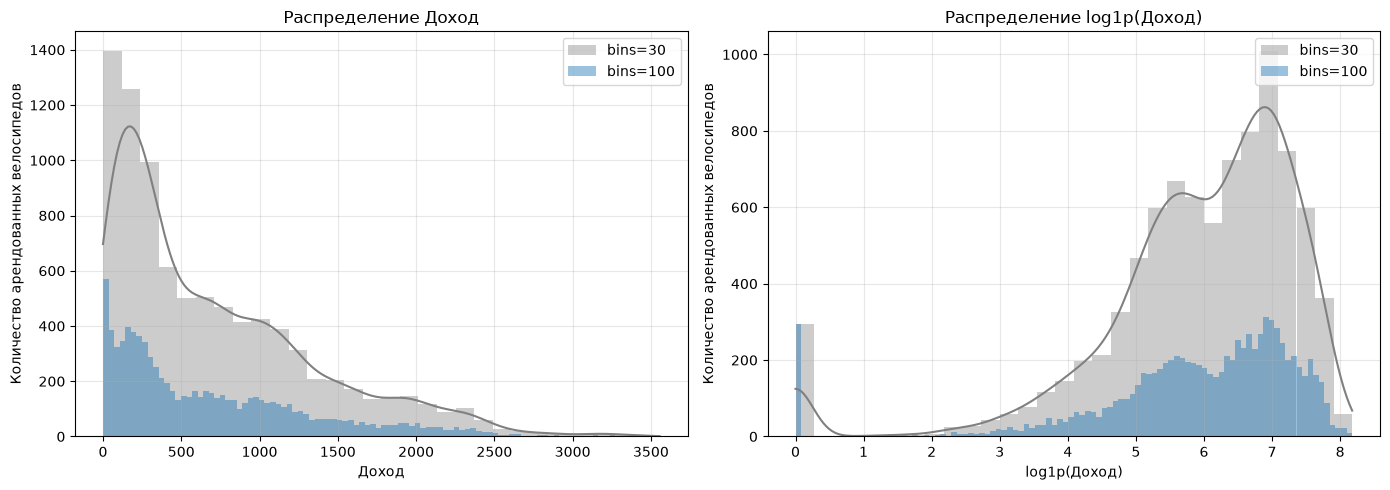

In [102]:
fig, axes = plot_distribution_pair(
    df['rented_bike_count'],
    feature_name="Доход",
    bins=(30, 100),
    kde=True,
    ylabel="Количество арендованных велосипедов",
    clip_quantiles=(0.00, 1.0),
)

In [103]:
target = df['rented_bike_count']

print("НУЛЕВЫЕ ЗНАЧЕНИЯ")
print("-" * 60)
zero_mask = target == 0
zero_cnt = zero_mask.sum()
print(f"Нулей всего:           {zero_cnt:,} ({zero_cnt / len(target) * 100:.2f}%)")

if 'functioning_day' in df.columns:
    zeros_non_func = df.loc[df['functioning_day'] == 'No', 'rented_bike_count'].eq(0).sum()
    zeros_func     = df.loc[df['functioning_day'] == 'Yes', 'rented_bike_count'].eq(0).sum()
    print(f"  из них Functioning Day = No:  {zeros_non_func:,}")
    print(f"  из них Functioning Day = Yes: {zeros_func:,}")

НУЛЕВЫЕ ЗНАЧЕНИЯ
------------------------------------------------------------
Нулей всего:           295 (3.37%)
  из них Functioning Day = No:  295
  из них Functioning Day = Yes: 0


Все нули объясняются нерабочими часами (не выбросы)

## Missing Values
[Table of Contents](#Table-of-Contents)

In [104]:
missing_values = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

pd.DataFrame({'Пропуски (шт)': missing_values, 'Пропуски (%)': missing_percent})

,Пропуски (шт),Пропуски (%)
date,0,0.0
rented_bike_count,0,0.0
hour,0,0.0
temperature,0,0.0
humidity,0,0.0
wind_speed,0,0.0
visibility,0,0.0
dew_point_temp,0,0.0
solar_radiation,0,0.0
rainfall,0,0.0


In [105]:
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates}")

time_duplicates = df.duplicated(subset=['date', 'hour']).sum()
print(f"Дубликатов по связке (date + hour): {time_duplicates}")

Полных дубликатов: 0
Дубликатов по связке (date + hour): 0


In [106]:
display(df.describe().T)

display(df.describe(include=['category', 'object']).T)

,count,mean,min,25%,50%,75%,max,std
date,8760,2018-06-01 00:00:00,2017-12-01 00:00:00,2018-03-02 00:00:00,2018-06-01 00:00:00,2018-08-31 00:00:00,2018-11-30 00:00:00,NaN
rented_bike_count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
temperature,8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
humidity,8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
wind_speed,8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
visibility,8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
dew_point_temp,8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
solar_radiation,8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
rainfall,8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193


,count,unique,top,freq
seasons,8760,4,Spring,2208
holiday,8760,2,No Holiday,8328
functioning_day,8760,2,Yes,8465


## Numerical Features and Anomalies
[Table of Contents](#Table-of-Contents)

### Numerical Features Index

- [Boxplot для всех численных признаков](#Boxplot-for-all-numerical-features)
- [Температура — обзор](#Temperature-Overview)
- [Влажность — обзор](#Humidity-Overview)
- [Скорость ветра — обзор](#Wind-Speed-Overview)
- [Видимость — обзор](#Visibility-Overview)
- [Температура точки росы — обзор](#Dew-Point-Temp-Overview)
- [Солнечная радиация — обзор](#Solar-Radiation-Overview)
- [Дождевые осадки — обзор](#Rainfall-Overview)
- [Снег — обзор](#Snowfall-Overview)

### Boxplot for all numerical features
[Индекс численных фичей](#Numerical-Features-Index)

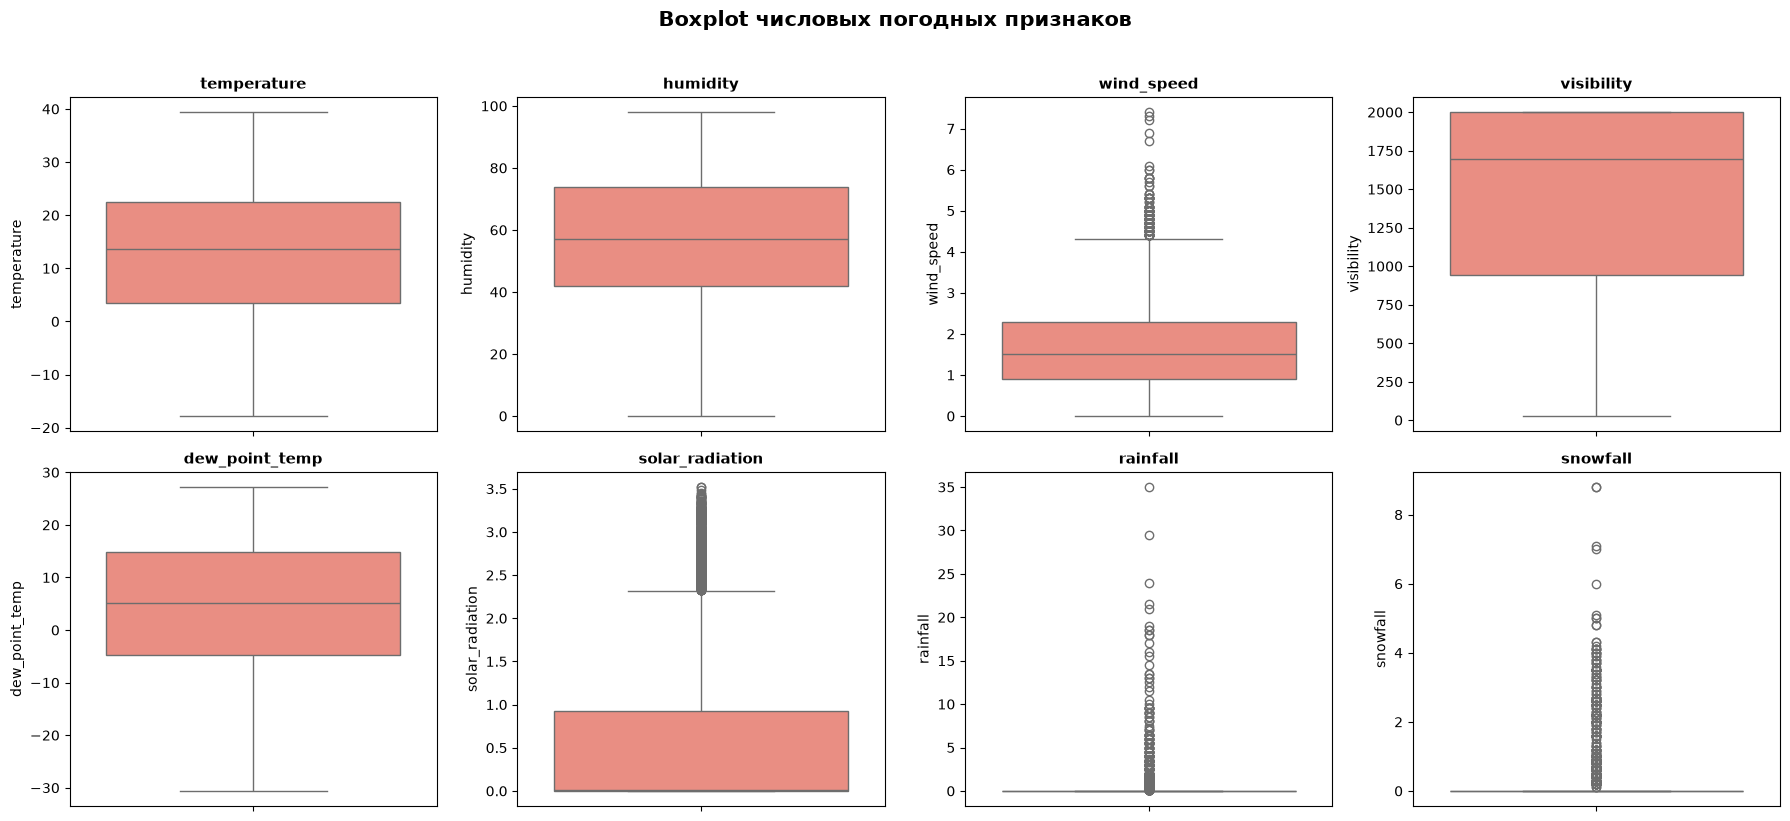

In [107]:
num_cols = [
    'temperature', 'humidity', 'wind_speed', 'visibility',
    'dew_point_temp', 'solar_radiation', 'rainfall', 'snowfall'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='salmon')
    axes[i].set_title(col, fontsize=11, fontweight='bold')

plt.suptitle('Boxplot числовых погодных признаков', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Temperature Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 12.8829 | Медиана: 13.7000 | Std: 11.9448
Min / Max: -17.8000 / 39.4000
Q1: 3.5000 | Q3: 22.5000 | IQR: 19.0000
IQR-пороги: [-25.0000, 51.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 21 (0.24%)
Асимметрия: -0.1983 | Эксцесс: -0.8378

Процентили:
0.000   -17.800
0.001   -16.200
0.010   -12.741
0.050    -7.100
0.250     3.500
0.500    13.700
0.750    22.500
0.950    30.700
0.990    35.100
0.999    37.800
1.000    39.400
Name: temperature, dtype: float64


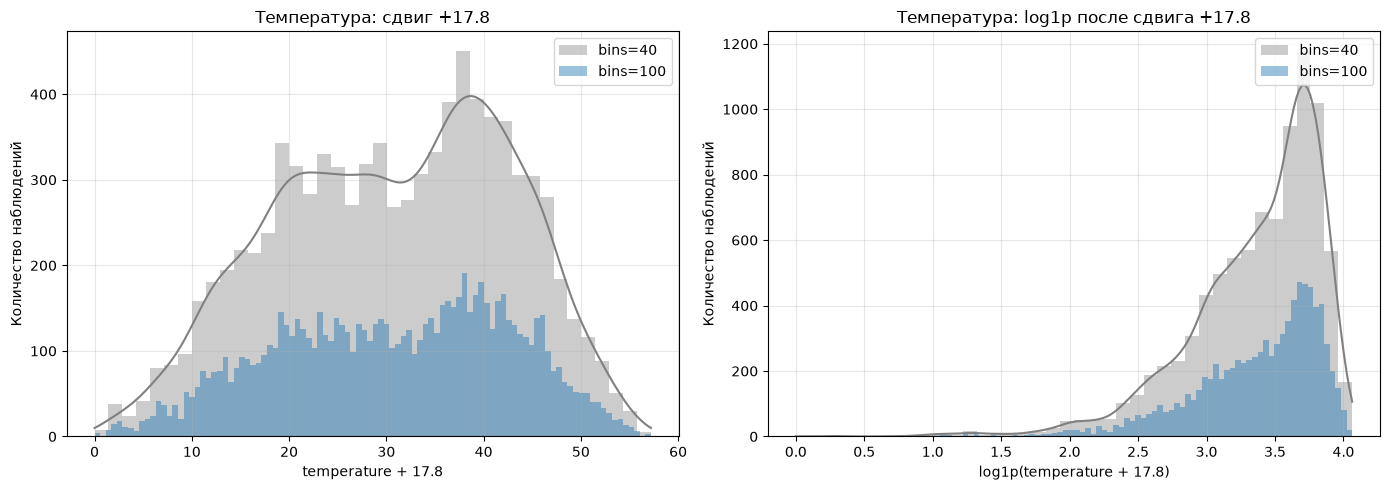

In [108]:
analyze_distribution(df["temperature"])

_ = plot_distribution_pair(
    df["temperature"] + 17.8,
    feature_name="temperature + 17.8",
    clip_quantiles=None,
    bins=(40, 100),
    kde=True,
    custom_titles=(
        "Температура: сдвиг +17.8",
        "Температура: log1p после сдвига +17.8",
    ),
)

### Humidity Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 58.2263 | Медиана: 57.0000 | Std: 20.3624
Min / Max: 0.0000 / 98.0000
Q1: 42.0000 | Q3: 74.0000 | IQR: 32.0000
IQR-пороги: [-6.0000, 122.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 17 (0.19%)
Асимметрия: 0.0596 | Эксцесс: -0.8036

Процентили:
0.000     0.0
0.001     0.0
0.010    17.0
0.050    27.0
0.250    42.0
0.500    57.0
0.750    74.0
0.950    94.0
0.990    97.0
0.999    98.0
1.000    98.0
Name: humidity, dtype: float64


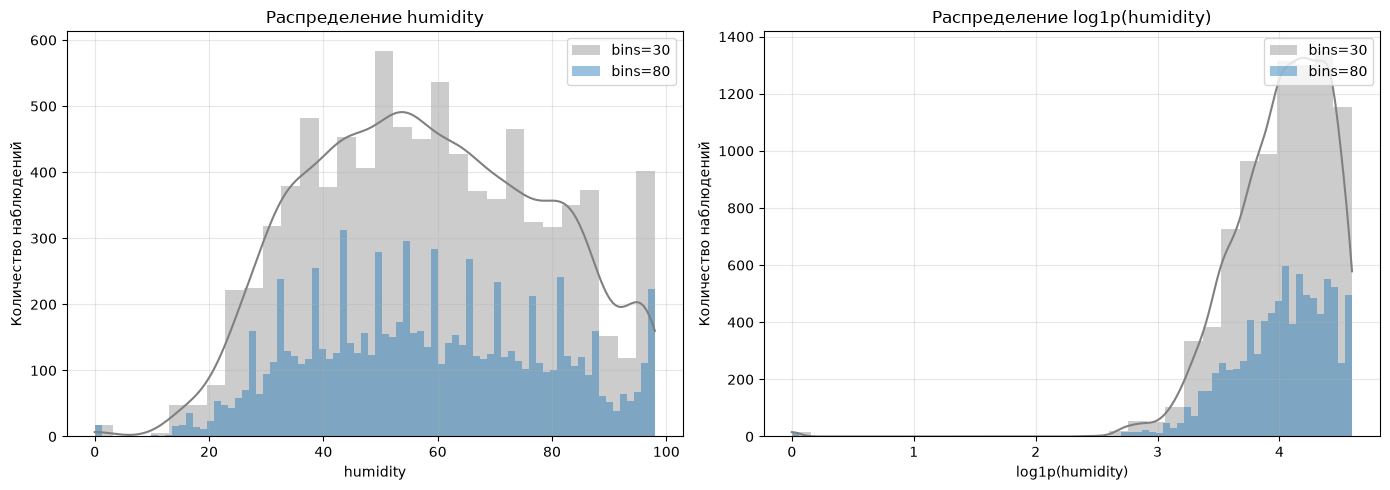

In [109]:
analyze_distribution(df["humidity"])

_ = plot_distribution_pair(
    df["humidity"],
    feature_name="humidity",
    clip_quantiles=None,
    bins=(30, 80),
    kde=True,
)

### Wind Speed Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 1.7249 | Медиана: 1.5000 | Std: 1.0363
Min / Max: 0.0000 / 7.4000
Q1: 0.9000 | Q3: 2.3000 | IQR: 1.4000
IQR-пороги: [-1.2000, 4.4000]
За IQR-порогами: 161 (1.84%) | Ниже: 0 | Выше: 161
Нули: 74 (0.84%)
Асимметрия: 0.8910 | Эксцесс: 0.7272

Процентили:
0.000    0.0
0.001    0.0
0.010    0.1
0.050    0.4
0.250    0.9
0.500    1.5
0.750    2.3
0.950    3.7
0.990    4.7
0.999    5.8
1.000    7.4
Name: wind_speed, dtype: float64


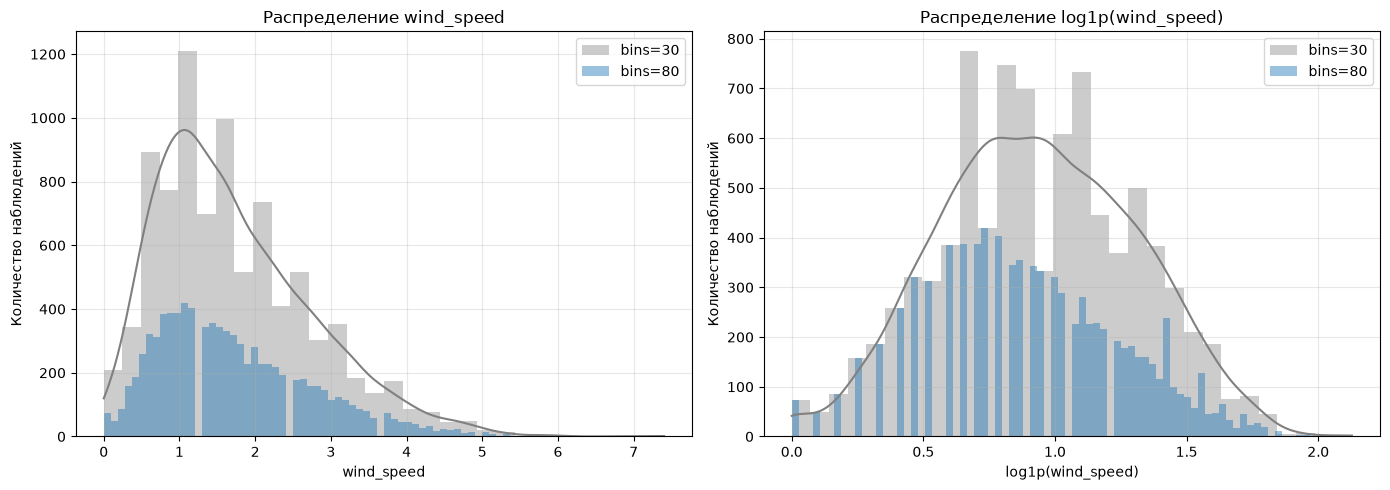

In [110]:
analyze_distribution(df["wind_speed"])

_ = plot_distribution_pair(
    df["wind_speed"],
    feature_name="wind_speed",
    clip_quantiles=None,
    bins=(30, 80),
    kde=True,
)

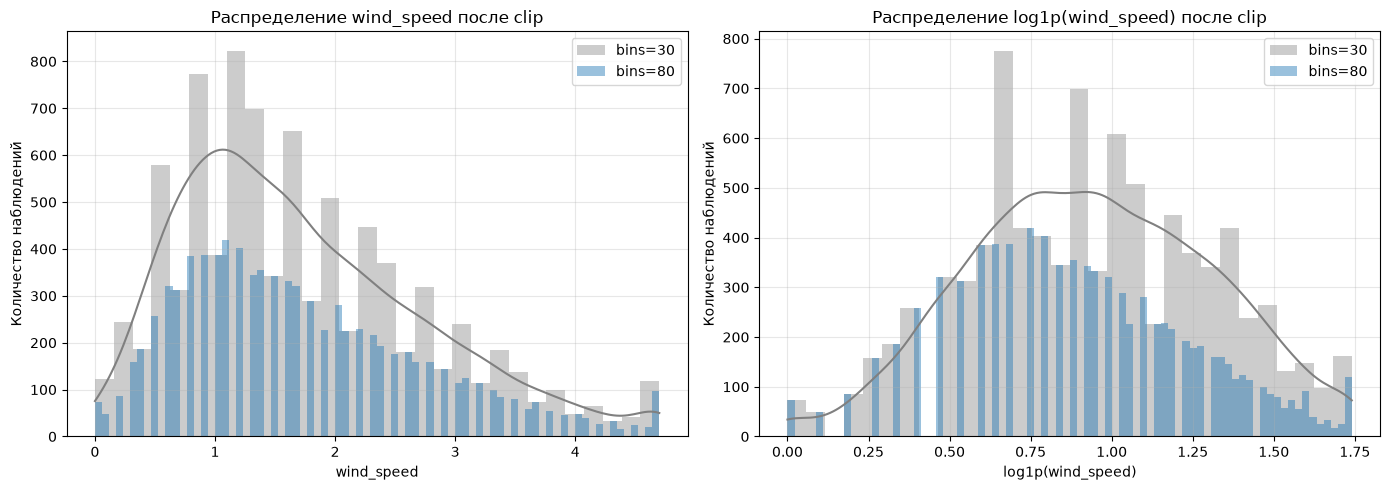

In [111]:
_ = plot_distribution_pair(
    df["wind_speed"],
    feature_name="wind_speed",
    clip_quantiles=(0.0, 0.99),
    bins=(30, 80),
    kde=True,
)

### Visibility Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 1436.8258 | Медиана: 1698.0000 | Std: 608.2987
Min / Max: 27.0000 / 2000.0000
Q1: 940.0000 | Q3: 2000.0000 | IQR: 1060.0000
IQR-пороги: [-650.0000, 3590.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 0 (0.00%)
Асимметрия: -0.7018 | Эксцесс: -0.9620

Процентили:
0.000      27.0
0.001      66.0
0.010     173.0
0.050     300.0
0.250     940.0
0.500    1698.0
0.750    2000.0
0.950    2000.0
0.990    2000.0
0.999    2000.0
1.000    2000.0
Name: visibility, dtype: float64


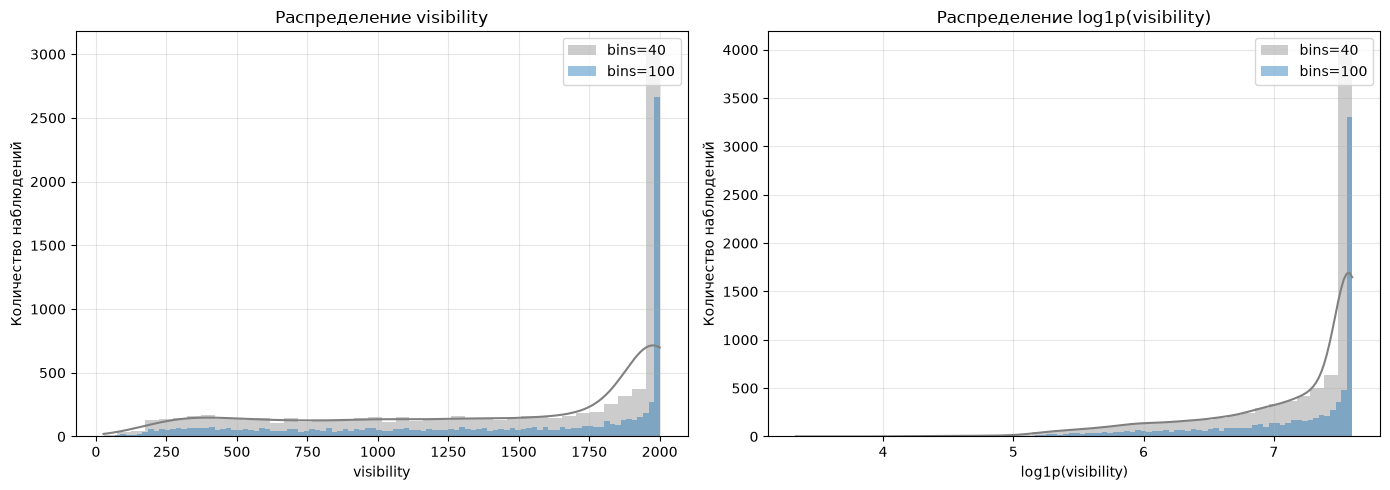

In [112]:
analyze_distribution(df["visibility"])

_ = plot_distribution_pair(
    df["visibility"],
    feature_name="visibility",
    clip_quantiles=None,
    bins=(40, 100),
    kde=True,
)

Всего: 6,515 | В анализе: 6,515
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 1242.7619 | Медиана: 1319.0000 | Std: 592.0974
Min / Max: 27.0000 / 1999.0000
Q1: 712.5000 | Q3: 1819.5000 | IQR: 1107.0000
IQR-пороги: [-948.0000, 3480.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 0 (0.00%)
Асимметрия: -0.3012 | Эксцесс: -1.2804

Процентили:
0.000      27.000
0.001      61.056
0.010     153.280
0.050     263.700
0.250     712.500
0.500    1319.000
0.750    1819.500
0.950    1985.000
0.990    1997.000
0.999    1999.000
1.000    1999.000
Name: visibility, dtype: float64


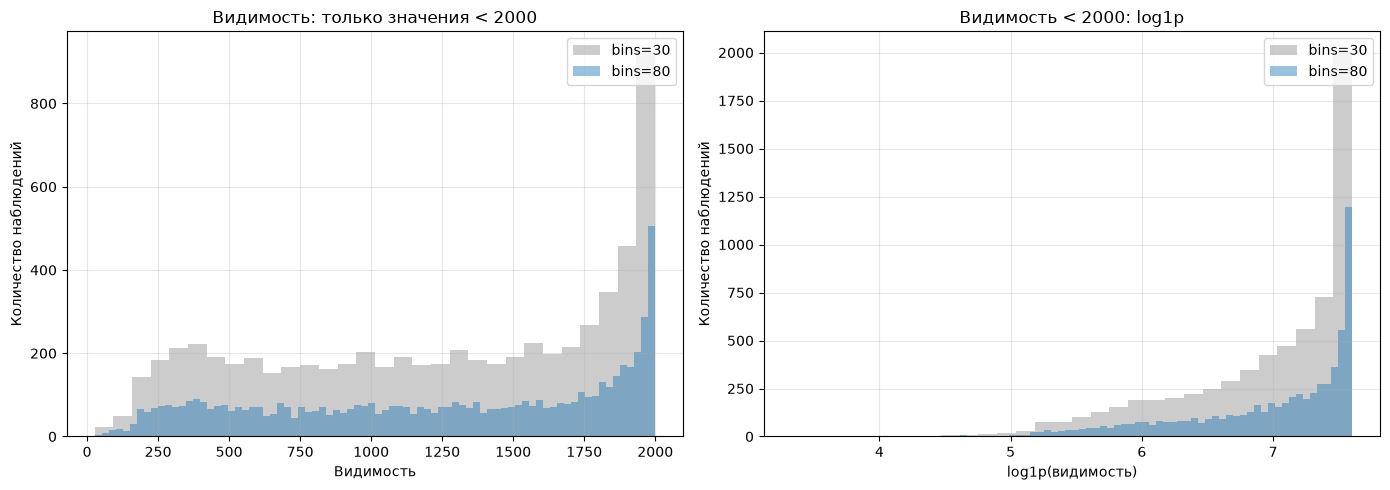

In [113]:
s_below_limit = s[s < 2000]

analyze_distribution(s_below_limit)

_ = plot_distribution_pair(
    s_below_limit,
    feature_name="visibility < 2000",
    clip_quantiles=None,
    bins=(30, 80),
    kde=False,
    custom_titles=(
        "Видимость: только значения < 2000",
        "Видимость < 2000: log1p",
    ),
    custom_xlabels=(
        "Видимость",
        "log1p(видимость)",
    ),
)

### Dew Point Temp Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 4.0738 | Медиана: 5.1000 | Std: 13.0604
Min / Max: -30.6000 / 27.2000
Q1: -4.7000 | Q3: 14.8000 | IQR: 19.5000
IQR-пороги: [-33.9500, 44.0500]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 60 (0.68%)
Асимметрия: -0.3673 | Эксцесс: -0.7554

Процентили:
0.000   -30.6000
0.001   -29.0241
0.010   -24.8000
0.050   -19.5050
0.250    -4.7000
0.500     5.1000
0.750    14.8000
0.950    22.4050
0.990    24.7000
0.999    26.0000
1.000    27.2000
Name: dew_point_temp, dtype: float64


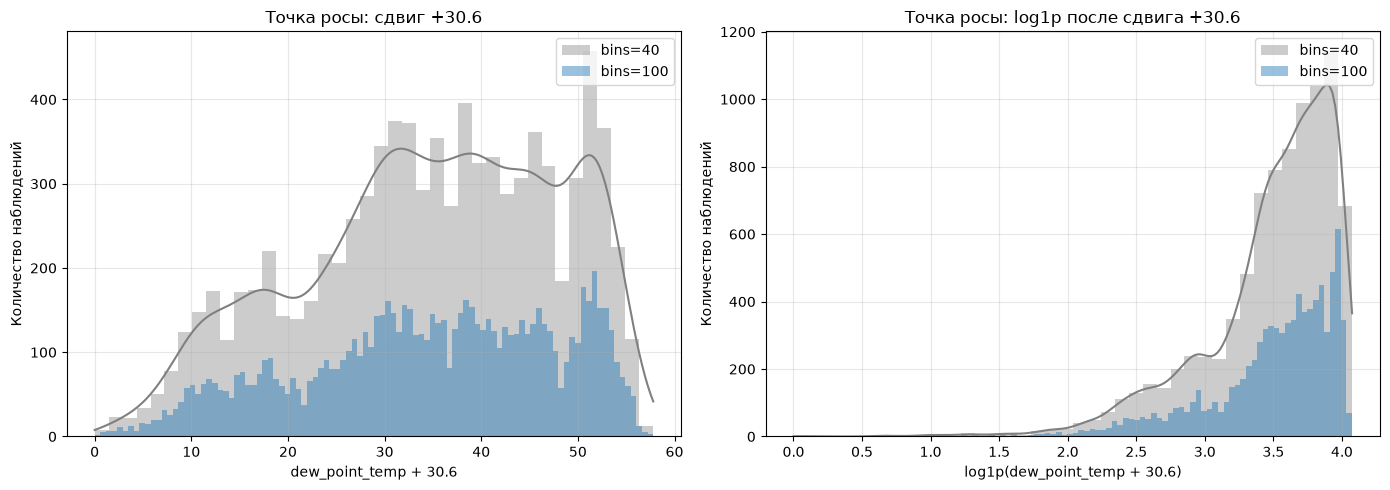

In [114]:
analyze_distribution(df["dew_point_temp"])

_ = plot_distribution_pair(
    df["dew_point_temp"] + 30.6,
    feature_name="dew_point_temp + 30.6",
    clip_quantiles=None,
    bins=(40, 100),
    kde=True,
    custom_titles=(
        "Точка росы: сдвиг +30.6",
        "Точка росы: log1p после сдвига +30.6",
    ),
)

### Solar Radiation Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 0.5691 | Медиана: 0.0100 | Std: 0.8687
Min / Max: 0.0000 / 3.5200
Q1: 0.0000 | Q3: 0.9300 | IQR: 0.9300
IQR-пороги: [-1.3950, 2.3250]
За IQR-порогами: 641 (7.32%) | Ниже: 0 | Выше: 641
Нули: 4,300 (49.09%)
Асимметрия: 1.5040 | Эксцесс: 1.1264

Процентили:
0.000    0.0000
0.001    0.0000
0.010    0.0000
0.050    0.0000
0.250    0.0000
0.500    0.0100
0.750    0.9300
0.950    2.5600
0.990    3.1700
0.999    3.4124
1.000    3.5200
Name: solar_radiation, dtype: float64


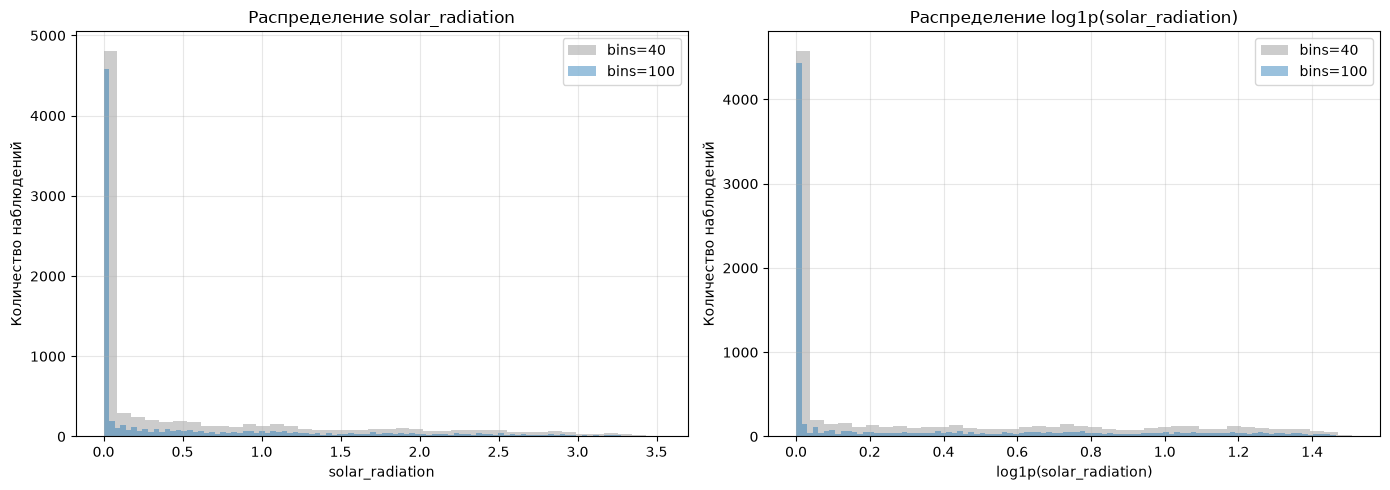

In [115]:
analyze_distribution(df["solar_radiation"])

_ = plot_distribution_pair(
    df["solar_radiation"],
    feature_name="solar_radiation",
    clip_quantiles=None,
    bins=(40, 100),
    kde=False,
)

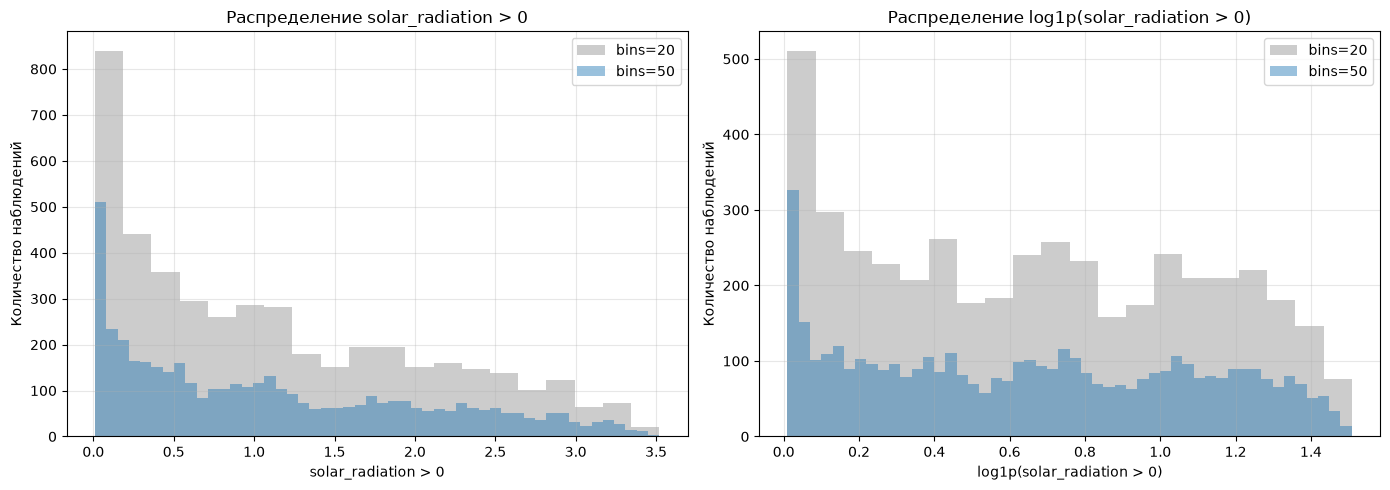

In [128]:
_ = plot_distribution_pair(
    df.loc[df["solar_radiation"] > 0, "solar_radiation"],
    feature_name="solar_radiation > 0",
    clip_quantiles=None,
    bins=(20, 50),
    kde=False,
)

### Rainfall Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 0.1487 | Медиана: 0.0000 | Std: 1.1282
Min / Max: 0.0000 / 35.0000
Q1: 0.0000 | Q3: 0.0000 | IQR: 0.0000
IQR-пороги: [0.0000, 0.0000]
За IQR-порогами: 528 (6.03%) | Ниже: 0 | Выше: 528
Нули: 8,232 (93.97%)
Асимметрия: 14.5332 | Эксцесс: 284.9911
Внимание: IQR = 0. Пороги совпадают; выход за них не означает ошибку данных.

Процентили:
0.000     0.0
0.001     0.0
0.010     0.0
0.050     0.0
0.250     0.0
0.500     0.0
0.750     0.0
0.950     0.4
0.990     4.0
0.999    18.0
1.000    35.0
Name: rainfall, dtype: float64


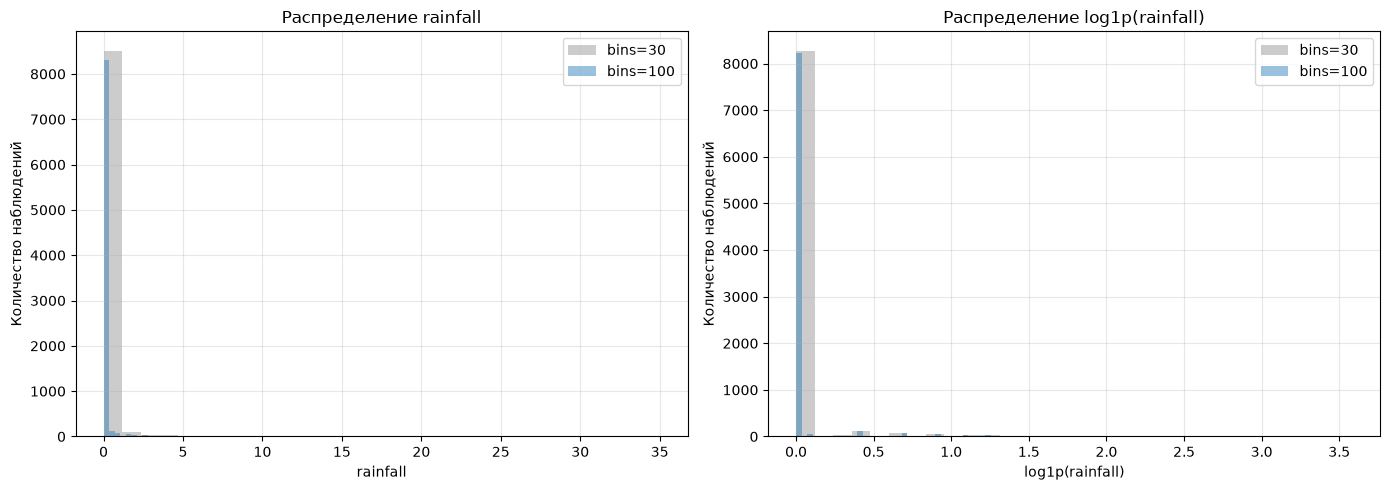

In [129]:
analyze_distribution(df["rainfall"])

_ = plot_distribution_pair(
    df["rainfall"],
    feature_name="rainfall",
    clip_quantiles=None,
    bins=(30, 100),
    kde=False,
)

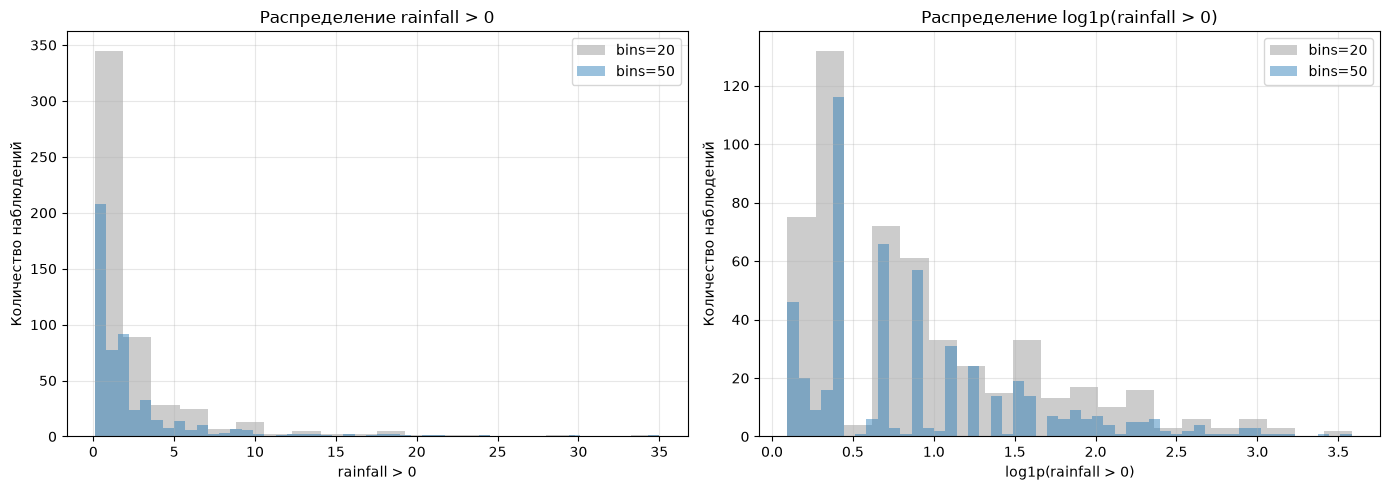

In [117]:
_ = plot_distribution_pair(
    df.loc[df["rainfall"] > 0, "rainfall"],
    feature_name="rainfall > 0",
    clip_quantiles=None,
    bins=(20, 50),
    kde=False,
)

### Snowfall Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 0.0751 | Медиана: 0.0000 | Std: 0.4367
Min / Max: 0.0000 / 8.8000
Q1: 0.0000 | Q3: 0.0000 | IQR: 0.0000
IQR-пороги: [0.0000, 0.0000]
За IQR-порогами: 443 (5.06%) | Ниже: 0 | Выше: 443
Нули: 8,317 (94.94%)
Асимметрия: 8.4408 | Эксцесс: 93.8033
Внимание: IQR = 0. Пороги совпадают; выход за них не означает ошибку данных.

Процентили:
0.000    0.0
0.001    0.0
0.010    0.0
0.050    0.0
0.250    0.0
0.500    0.0
0.750    0.0
0.950    0.2
0.990    2.5
0.999    4.8
1.000    8.8
Name: snowfall, dtype: float64


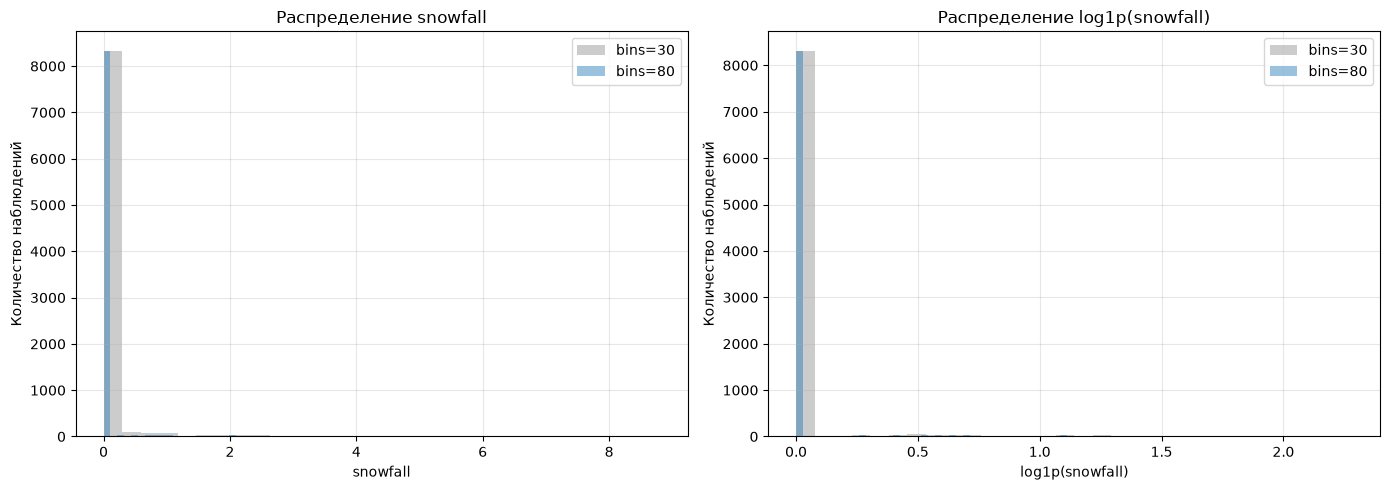

In [118]:
analyze_distribution(df["snowfall"])

_ = plot_distribution_pair(
    df["snowfall"],
    feature_name="snowfall",
    clip_quantiles=None,
    bins=(30, 80),
    kde=False,
)

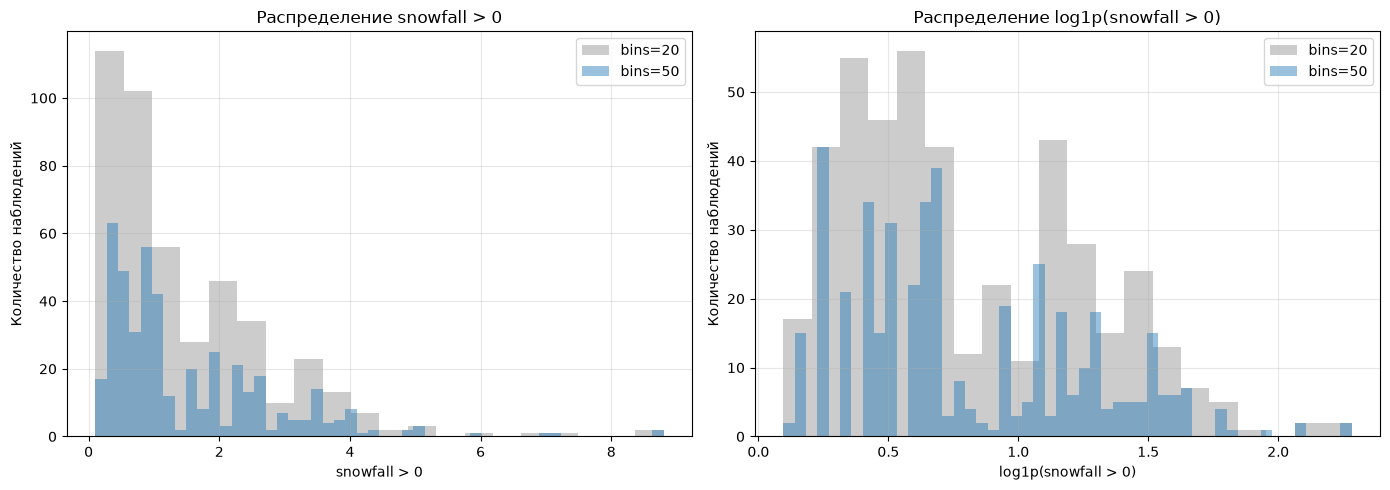

In [119]:
_ = plot_distribution_pair(
    df.loc[df["snowfall"] > 0, "snowfall"],
    feature_name="snowfall > 0",
    clip_quantiles=None,
    bins=(20, 50),
    kde=False,
)

| Название признака | Что означает | Есть ли пропуски | Есть ли пики / скопления | Есть ли выбросы по IQR | Асимметрия | Нужно ли клипировать | Резюме по признаку |
|---|---|---|---|---|---|---|---|
| temperature | Температура воздуха | Нет | Уточнить по гистограмме | Нет | Слабая левосторонняя, skew = −0.20 | Пока нет | Диапазон от −17.8 до 39.4. Сохранить исходные значения. Сдвиг +17.8 используется только для визуального сравнения с log1p |
| humidity | Относительная влажность воздуха | Нет NaN; проверить 17 нулевых значений (0.19%) | Уточнить по гистограмме | Нет | Почти симметричное распределение, skew = 0.06 | Пока нет | Проверить происхождение нулей. До проверки не заменять их и не удалять строки |
| wind_speed | Скорость ветра | Нет | Уточнить по гистограмме; нулей 0.84% | 161 значение (1.84%) выше верхнего IQR-порога | Правосторонняя, skew = 0.89 | Пока нет; можно сравнить с clip (0.0, 0.99) | Есть верхний хвост до 7.4. Выходы за IQR-порог не считать ошибками без дополнительной проверки |
| visibility | Видимость; единицы уточнить по описанию данных | Нет | Скопление на максимуме 2000; Q3 = 2000 | Нет | Левосторонняя, skew = −0.70 | Пока нет | Уточнить смысл максимума 2000 и его долю. Дополнительно рассмотреть распределение значений < 2000 |
| dew_point_temp | Температура точки росы | Нет | Уточнить по гистограмме | Нет | Слабая левосторонняя, skew = −0.37 | Пока нет | Диапазон от −30.6 до 27.2. Сохранить исходные значения. Сдвиг +30.6 используется только для визуального сравнения с log1p |
| solar_radiation | Солнечная радиация; единицы уточнить по описанию данных | Нет | Скопление в нуле: 4300 значений (49.09%) | 641 значение (7.32%) выше верхнего IQR-порога | Правосторонняя, skew = 1.50 | Пока нет | Рассмотреть нули и положительные значения отдельно. Не считать верхний хвост ошибкой только по IQR |
| rainfall | Количество дождевых осадков; единицы и период измерения уточнить | Нет | Выраженное скопление в нуле: 8232 значения (93.97%) | 528 значений (6.03%); при IQR = 0 это все положительные значения | Сильная правосторонняя, skew = 14.53 | Не применять IQR-клипирование: оно обнулит все положительные значения | Отдельно изучить наличие дождя и величину осадков при rainfall > 0. Рассмотреть индикатор наличия дождя как дополнительный признак |
| snowfall | Показатель снега; точный смысл и единицы уточнить по описанию данных | Нет | Выраженное скопление в нуле: 8317 значений (94.94%) | 443 значения (5.06%); при IQR = 0 это все положительные значения | Сильная правосторонняя, skew = 8.44 | Не применять IQR-клипирование: оно обнулит все положительные значения | Отдельно изучить нули и snowfall > 0. Рассмотреть индикатор наличия снега как дополнительный признак |

## Categorical Features and Target
[Table of Contents](#Table-of-Contents)

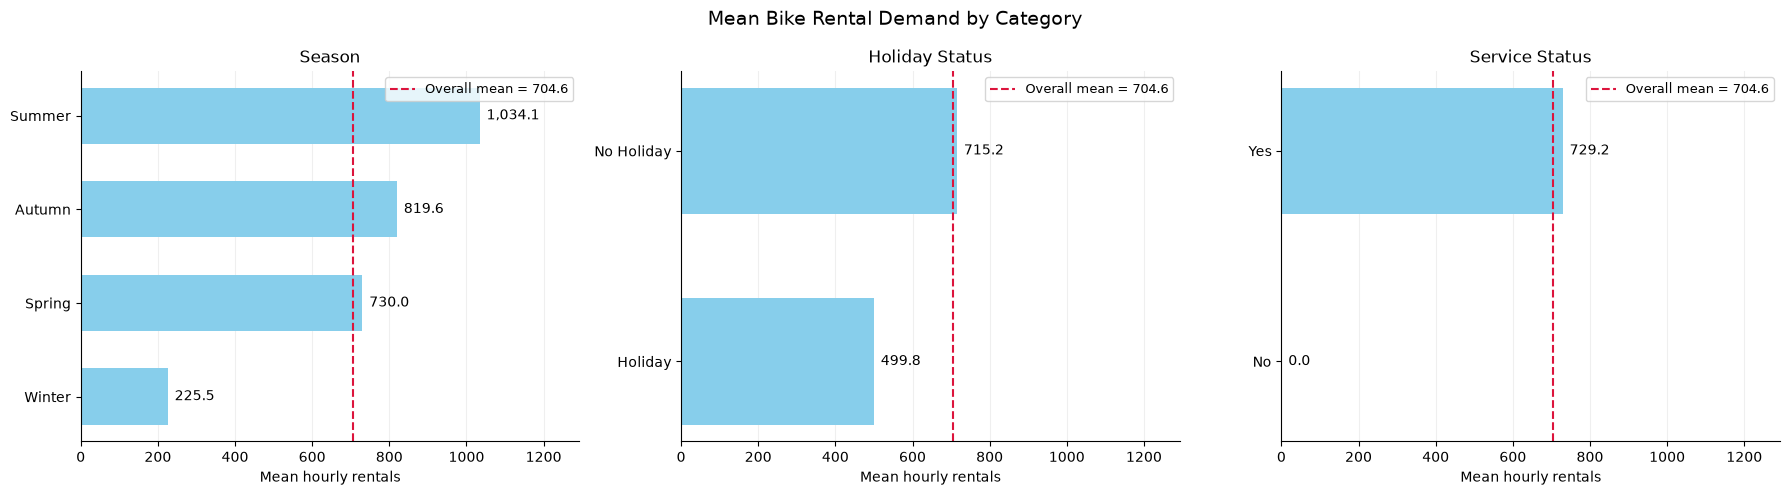


seasons


,n,mean,median,std,share_pct
seasons,,,,,
Autumn,2184,819.60,763.5,651.09,24.93
Spring,2208,730.03,583.0,621.51,25.21
Summer,2208,1034.07,905.5,690.24,25.21
Winter,2160,225.54,203.0,150.37,24.66



holiday


,n,mean,median,std,share_pct
holiday,,,,,
Holiday,432,499.76,240.0,570.77,4.93
No Holiday,8328,715.23,524.5,646.88,95.07



functioning_day


,n,mean,median,std,share_pct
functioning_day,,,,,
No,295,0.00,0.0,0.00,3.37
Yes,8465,729.16,542.0,642.35,96.63



SERVICE DOWNTIME CHECK
Нерабочих часов: 295
Из них с нулевыми арендами: 295
Из них с пропущенным таргетом: 0
Во всех наблюдаемых нерабочих часах количество аренд равно 0.


In [154]:
import matplotlib.pyplot as plt
import pandas as pd

cat_cols = ["seasons", "holiday", "functioning_day"]
target_col = "rented_bike_count"

# Все расчёты выполняются на полном df, включая часы остановок.
baseline = df[target_col].mean()

titles = {
    "seasons": "Season",
    "holiday": "Holiday Status",
    "functioning_day": "Service Status",
}

# Статистики рассчитываем один раз.
category_stats = {}

for col in cat_cols:
    stats = (
        df.groupby(col, observed=True)[target_col]
        .agg(
            n="size",
            mean="mean",
            median="median",
            std="std",
        )
    )

    stats["share_pct"] = stats["n"] / len(df) * 100
    category_stats[col] = stats

# Графики: три панели в ряд, одинаковый масштаб.
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
)

max_mean = max(
    stats["mean"].max()
    for stats in category_stats.values()
)
x_max = max(max_mean, baseline) * 1.25

for ax, col in zip(axes, cat_cols):
    means = (
        category_stats[col]["mean"]
        .dropna()
        .sort_values(ascending=False)
    )

    positions = np.arange(len(means))

    bars = ax.barh(
        positions,
        means.to_numpy(),
        color="skyblue",
        height=0.6,
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(means.index.astype(str))
    ax.invert_yaxis()

    ax.axvline(
        baseline,
        color="crimson",
        linestyle="--",
        linewidth=1.5,
        label=f"Overall mean = {baseline:,.1f}",
    )

    ax.bar_label(
        bars,
        labels=[f"{value:,.1f}" for value in means],
        padding=5,
        fontsize=10,
    )

    ax.set_title(titles[col], fontsize=12)
    ax.set_xlabel("Mean hourly rentals")
    ax.set_xlim(0, x_max)

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", fontsize=9)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Mean Bike Rental Demand by Category",
    fontsize=14,
)

fig.tight_layout()
plt.show()

# Таблицы статистик.
for col, stats in category_stats.items():
    print(f"\n{col}")
    display(stats.round(2))

# Отдельная проверка аренд во время остановок сервиса.
non_func = df.loc[
    df["functioning_day"].eq("No"),
    target_col,
]

print("\nSERVICE DOWNTIME CHECK")
print(f"Нерабочих часов: {len(non_func):,}")
print(f"Из них с нулевыми арендами: {non_func.eq(0).sum():,}")
print(f"Из них с пропущенным таргетом: {non_func.isna().sum():,}")

if (
    not non_func.empty
    and non_func.notna().all()
    and non_func.eq(0).all()
):
    print("Во всех наблюдаемых нерабочих часах количество аренд равно 0.")

In [152]:
for col, stats in category_stats.items():
    print(f"\n{col}")
    display(stats.round(2))


seasons


,n,n_target,mean,median,std,share_pct
seasons,,,,,,
Autumn,2184,2184,819.60,763.5,651.09,24.93
Spring,2208,2208,730.03,583.0,621.51,25.21
Summer,2208,2208,1034.07,905.5,690.24,25.21
Winter,2160,2160,225.54,203.0,150.37,24.66



holiday


,n,n_target,mean,median,std,share_pct
holiday,,,,,,
Holiday,432,432,499.76,240.0,570.77,4.93
No Holiday,8328,8328,715.23,524.5,646.88,95.07



functioning_day


,n,n_target,mean,median,std,share_pct
functioning_day,,,,,,
No,295,295,0.00,0.0,0.00,3.37
Yes,8465,8465,729.16,542.0,642.35,96.63


## Feature Correlations
[Table of Contents](#Table-of-Contents)

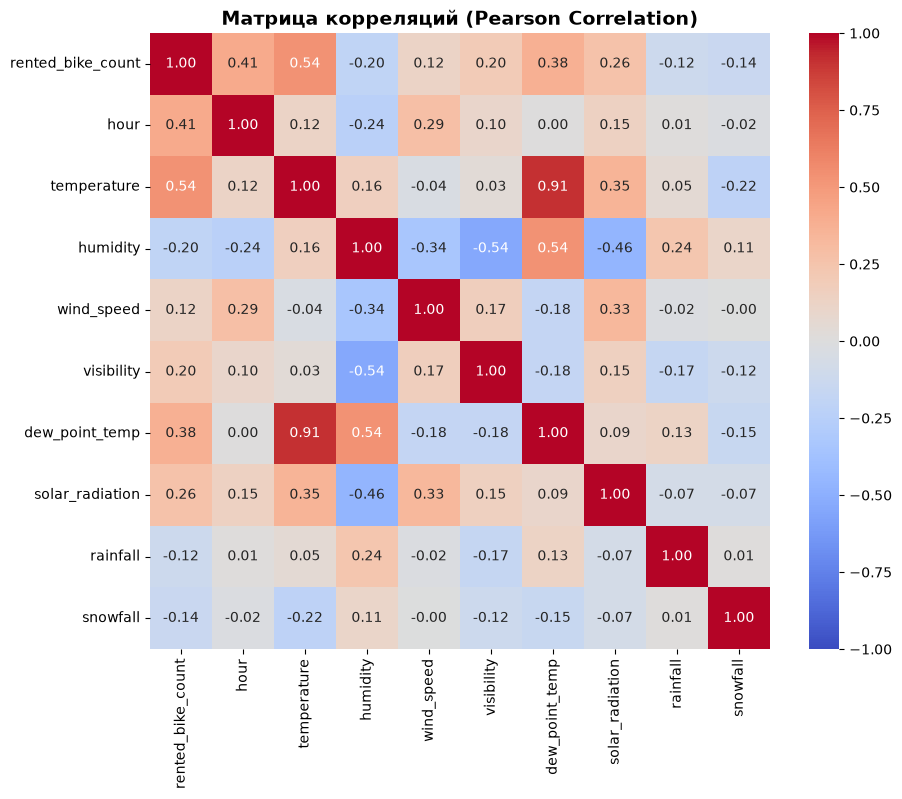

In [122]:
plt.figure(figsize=(10, 8))

corr = df.select_dtypes(include=['float64', 'int64']).corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляций (Pearson Correlation)', fontsize=14, fontweight='bold')
plt.show()

In [123]:
corr 

,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temp,solar_radiation,rainfall,snowfall
rented_bike_count,1.000000,0.410257,0.538558,-0.199780,0.121108,0.199280,0.379788,0.261837,-0.123074,-0.141804
hour,0.410257,1.000000,0.124114,-0.241644,0.285197,0.098753,0.003054,0.145131,0.008715,-0.021516
temperature,0.538558,0.124114,1.000000,0.159371,-0.036252,0.034794,0.912798,0.353505,0.050282,-0.218405
humidity,-0.199780,-0.241644,0.159371,1.000000,-0.336683,-0.543090,0.536894,-0.461919,0.236397,0.108183
wind_speed,0.121108,0.285197,-0.036252,-0.336683,1.000000,0.171507,-0.176486,0.332274,-0.019674,-0.003554
visibility,0.199280,0.098753,0.034794,-0.543090,0.171507,1.000000,-0.176630,0.149738,-0.167629,-0.121695
dew_point_temp,0.379788,0.003054,0.912798,0.536894,-0.176486,-0.176630,1.000000,0.094381,0.125597,-0.150887
solar_radiation,0.261837,0.145131,0.353505,-0.461919,0.332274,0.149738,0.094381,1.000000,-0.074290,-0.072301
rainfall,-0.123074,0.008715,0.050282,0.236397,-0.019674,-0.167629,0.125597,-0.074290,1.000000,0.008500
snowfall,-0.141804,-0.021516,-0.218405,0.108183,-0.003554,-0.121695,-0.150887,-0.072301,0.008500,1.000000


### Feature Dependencies — Phi-K Correlation

Анализ попарных зависимостей числовых и категориальных переменных.
Phi-K используется для выявления в том числе нелинейных связей.

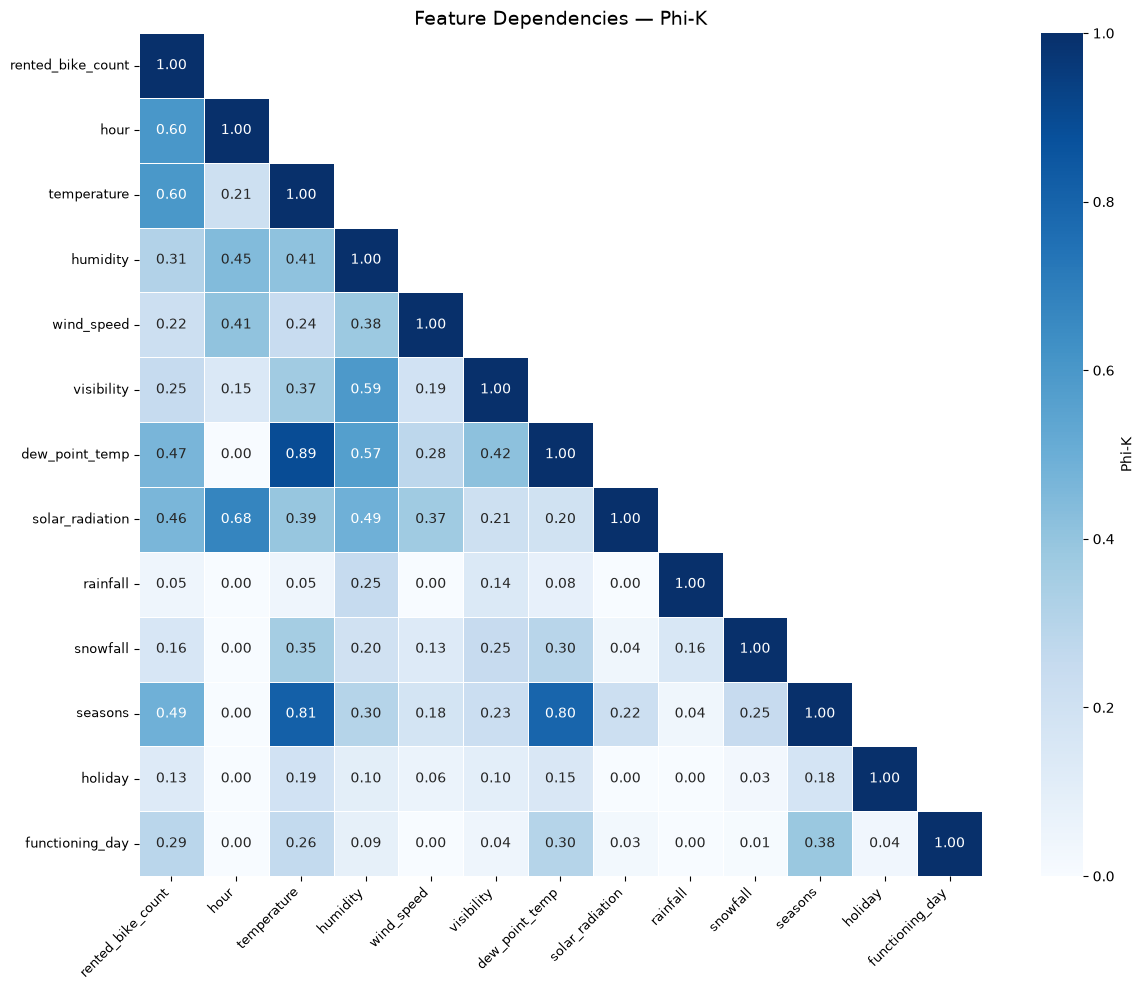

In [156]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

weather_cols = [
    "temperature",
    "humidity",
    "wind_speed",
    "visibility",
    "dew_point_temp",
    "solar_radiation",
    "rainfall",
    "snowfall",
]

categorical_cols = [
    "seasons",
    "holiday",
    "functioning_day",
]

target_col = "rented_bike_count"

analysis_cols = (
    [target_col, "hour"]
    + weather_cols
    + categorical_cols
)

dependency_data = df[analysis_cols].copy()

# Непрерывные/количественные переменные для разбиения на интервалы.
# hour оставляем как 24 отдельных значения.
interval_cols = [target_col] + weather_cols

phik_corr = dependency_data.phik_matrix(
    interval_cols=interval_cols,
    bins=10,
    quantile=False,
    noise_correction=True,
    verbose=False,
    njobs=1,
)

# Сохраняем выбранный порядок переменных.
phik_corr = phik_corr.loc[analysis_cols, analysis_cols]

# Скрываем только верхнюю половину: матрица симметрична.
mask = np.triu(
    np.ones_like(phik_corr, dtype=bool),
    k=1,
)

fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(
    phik_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.4,
    cbar_kws={"label": "Phi-K"},
    ax=ax,
)

ax.set_title("Feature Dependencies — Phi-K", fontsize=14)
ax.tick_params(axis="both", labelsize=9)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)

fig.tight_layout()
plt.show()

### Numerical Feature Relationships — Pairplot

Визуальная проверка формы попарных связей числовых признаков:
линейности, нелинейности, скоплений и ограничений диапазона.

In [157]:
feature_phik = phik_corr.drop(
    index=target_col,
    columns=target_col,
)

upper_mask = np.triu(
    np.ones(feature_phik.shape, dtype=bool),
    k=1,
)

top_feature_pairs = (
    feature_phik
    .where(upper_mask)
    .stack()
    .rename("phi_k")
    .sort_values(ascending=False)
    .reset_index()
)

top_feature_pairs.columns = ["feature_1", "feature_2", "phi_k"]

display(top_feature_pairs.head(15).round(3))

,feature_1,feature_2,phi_k
0,temperature,dew_point_temp,0.893
1,temperature,seasons,0.813
2,dew_point_temp,seasons,0.796
3,hour,solar_radiation,0.676
4,humidity,visibility,0.590
5,humidity,dew_point_temp,0.570
6,humidity,solar_radiation,0.489
7,hour,humidity,0.445
8,visibility,dew_point_temp,0.418
9,temperature,humidity,0.413


### Numerical Feature Relationships — Pairplot

Визуальная проверка формы попарных связей числовых признаков:
линейности, нелинейности, скоплений и ограничений диапазона.

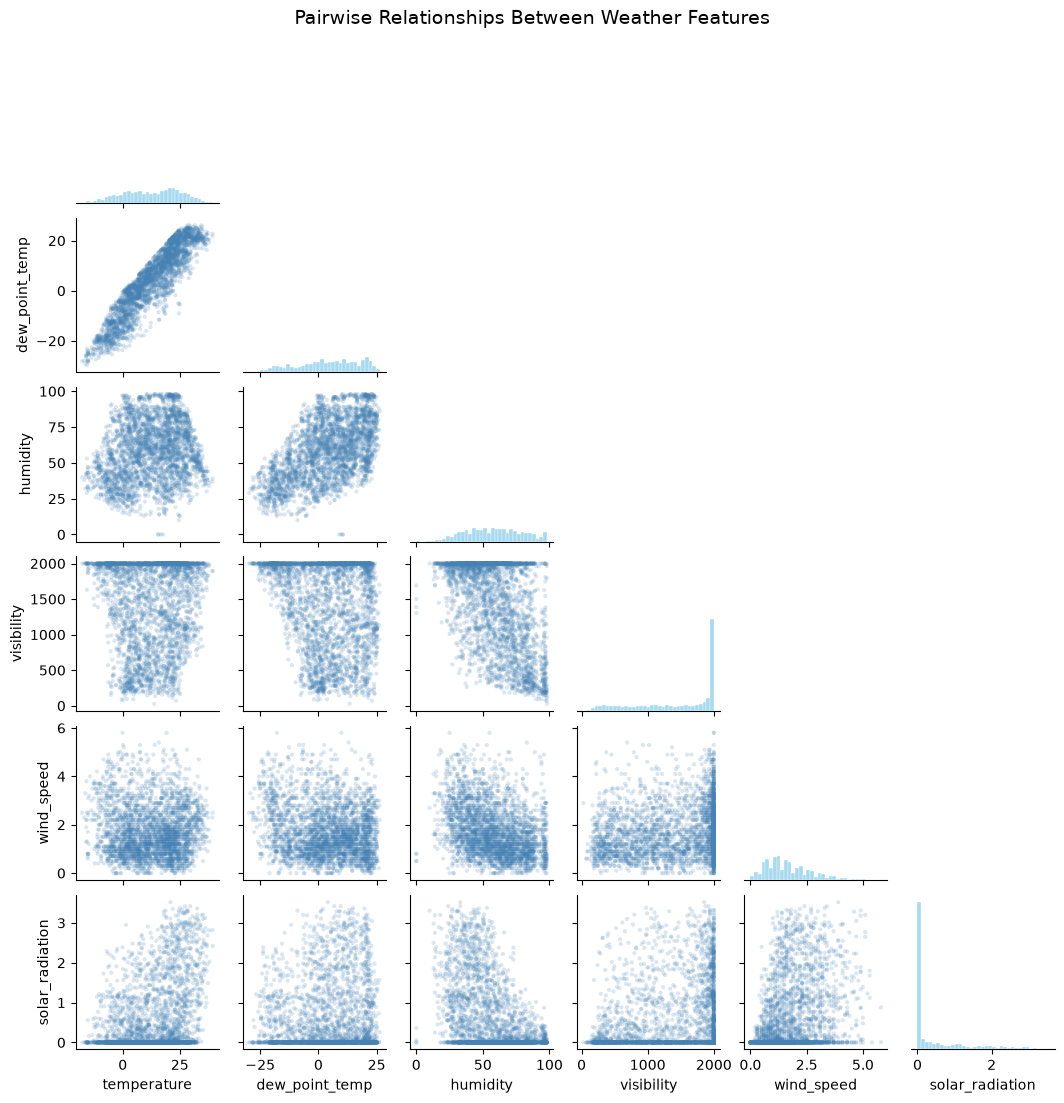

In [158]:
pair_cols = [
    "temperature",
    "dew_point_temp",
    "humidity",
    "visibility",
    "wind_speed",
    "solar_radiation",
]

# Выборка используется только для читаемости графика.
# Phi-K выше рассчитан по всему df.
pair_data = df[pair_cols].sample(
    n=min(3000, len(df)),
    random_state=42,
)

g = sns.pairplot(
    data=pair_data,
    corner=True,
    diag_kind="hist",
    height=1.8,
    plot_kws={
        "s": 9,
        "alpha": 0.2,
        "color": "steelblue",
        "edgecolor": "none",
    },
    diag_kws={
        "bins": 35,
        "color": "skyblue",
        "edgecolor": "white",
    },
)

g.figure.suptitle(
    "Pairwise Relationships Between Weather Features",
    fontsize=14,
    y=1.02,
)

plt.show()

### Feature Dependencies — Summary

#### Связи между признаками

- Наиболее сильная зависимость выявлена между temperature
  и dew_point_temp: Phi-K = 0.893. На pairplot видна узкая
  возрастающая полоса, подтверждающая выраженную положительную связь.
  Это основная пара для проверки возможного дублирования информации.

- Сезон тесно связан с температурой воздуха (Phi-K = 0.813)
  и температурой точки росы (0.796). Эти признаки содержат
  пересекающуюся информацию о сезонных условиях, но не являются
  взаимозаменяемыми автоматически.

- Между hour и solar_radiation наблюдается выраженная зависимость
  (Phi-K = 0.676). Её форму следует отдельно рассмотреть
  на графике солнечной радиации по часам.

- Заметные зависимости также выявлены для humidity и visibility
  (Phi-K = 0.590), humidity и dew_point_temp (0.570).
  Pairplot показывает тенденцию к снижению видимости
  при высокой влажности и росту температуры точки росы
  с увеличением влажности.

#### Связи с целевой переменной

- Наибольшие значения Phi-K с rented_bike_count среди рассмотренных
  признаков имеют hour и temperature — около 0.60.
- Далее следуют seasons (около 0.49), dew_point_temp (0.47)
  и solar_radiation (0.46).
- Эти значения описывают попарные зависимости и не являются
  рейтингом важности признаков для будущей модели.
- Низкие значения Phi-K для rainfall и snowfall не доказывают
  отсутствия их влияния: в этих признаках преобладают нули,
  а числовые переменные при расчёте разбиваются на интервалы.

#### Наблюдения по Pairplot

- Видно выраженное скопление visibility на верхней границе 2000.
  Точный смысл этой границы нужно уточнить по описанию данных.
- У solar_radiation заметна большая концентрация нулевых значений.
- Для большинства остальных показанных пар нет столь же узкой
  зависимости, как у temperature и dew_point_temp.
  Это не исключает нелинейных связей и взаимодействий.

#### Решения для дальнейшего моделирования

- На этапе EDA признаки не удалять.
- Проверить качество моделей с обоими температурными признаками
  и без одного из них на одинаковой временной валидации.
- Отдельно проверить, даёт ли seasons дополнительную информацию
  при наличии погодных и календарных признаков.
- Сохранить матрицу Пирсона как дополнение:
  она показывает направление линейной связи, которого нет у Phi-K.

#### Ограничения интерпретации

- Высокая попарная зависимость не означает причинность
  и не доказывает, что один из признаков необходимо исключить.
- Phi-K оценивает силу зависимости без её направления;
  результат зависит в том числе от разбиения числовых значений
  на интервалы.
- Матрица попарных зависимостей сама по себе не является
  полной диагностикой мультиколлинеарности.

## Temporal and Demand Dynamics

[Table of Contents](#Table-of-Contents)


### Time-Series EDA Index

- [Проверка временного покрытия, пропущенных часов и дубликатов](#Temporal-Integrity-Check)
- [Суточный спрос и скользящее среднее за 7 дней](#Daily-Demand-Over-Time)
- [Почасовые профили спроса по типам дней](#Hourly-Demand-by-Day-Type)
- [Автокорреляция спроса и лаги 1, 24 и 168 часов](#Demand-Autocorrelation)
- [Итоги временного EDA: наблюдения, ограничения и кандидаты в признаки](#Time-Series-EDA-Summary)

### Temporal Integrity Check
[Index](#Time-Series-EDA-Index)

Проверка покрытия периода с 1 декабря 2017 года по 30 ноября 2018 года:
корректность часов, пропущенные временные отметки, дубликаты
и полнота каждого календарного дня.

In [131]:
time_check = df[["date", "hour"]].copy()

hours = pd.to_numeric(time_check["hour"], errors="coerce")

invalid_dates = (
    time_check["date"].isna()
    | time_check["date"].ne(time_check["date"].dt.normalize())
)

invalid_hours = (
    hours.isna()
    | ~hours.between(0, 23)
    | hours.mod(1).ne(0)
)

if invalid_dates.any() or invalid_hours.any():
    print(f"Некорректных дат: {invalid_dates.sum():,}")
    print(f"Некорректных часов: {invalid_hours.sum():,}")

    display(time_check.loc[invalid_dates | invalid_hours])

    raise ValueError(
        "Сначала исправь даты и часы: date должен содержать дату "
        "без времени, hour — целое число от 0 до 23."
    )

time_check["datetime"] = (
    time_check["date"]
    + pd.to_timedelta(hours.astype(int), unit="h")
)

was_sorted = time_check["datetime"].is_monotonic_increasing
time_check = time_check.sort_values("datetime")

expected_hours = pd.date_range(
    start="2017-12-01 00:00",
    end="2018-11-30 23:00",
    freq="h",
)

actual_hours = pd.DatetimeIndex(time_check["datetime"].unique())

missing_hours = expected_hours.difference(actual_hours)
extra_hours = actual_hours.difference(expected_hours)

n_duplicates = time_check["datetime"].duplicated().sum()

duplicate_rows = time_check.loc[
    time_check["datetime"].duplicated(keep=False)
]

expected_days = pd.date_range(
    start="2017-12-01",
    end="2018-11-30",
    freq="D",
)

hours_per_day = (
    time_check
    .groupby(time_check["datetime"].dt.normalize())["datetime"]
    .nunique()
    .reindex(expected_days, fill_value=0)
    .rename("unique_hours")
)

incomplete_days = hours_per_day[hours_per_day.ne(24)]

is_complete = (
    len(missing_hours) == 0
    and len(extra_hours) == 0
    and n_duplicates == 0
    and incomplete_days.empty
)

print("=" * 70)
print("TEMPORAL INTEGRITY CHECK")
print("=" * 70)

print(f"Начало данных:                 {time_check['datetime'].min()}")
print(f"Конец данных:                  {time_check['datetime'].max()}")
print(f"Ожидаемое количество часов:     {len(expected_hours):,}")
print(f"Фактическое количество строк:   {len(time_check):,}")
print(f"Уникальных временных отметок:   {len(actual_hours):,}")
print(f"Пропущенных часов:              {len(missing_hours):,}")
print(f"Часов вне ожидаемого периода:   {len(extra_hours):,}")
print(f"Дублирующих строк по времени:   {n_duplicates:,}")
print(f"Дней с количеством часов != 24: {len(incomplete_days):,}")
print(f"Исходный порядок хронологический: {was_sorted}")

print(
    "\nИтог:",
    "Период покрыт полностью, каждый час представлен ровно один раз."
    if is_complete
    else "Обнаружены проблемы временного покрытия — смотри детали ниже."
)

if len(missing_hours):
    print("\nПропущенные часы — первые 20:")
    display(missing_hours.to_frame(index=False, name="datetime").head(20))

if len(extra_hours):
    print("\nЧасы вне ожидаемого периода — первые 20:")
    display(extra_hours.to_frame(index=False, name="datetime").head(20))

if n_duplicates:
    print("\nСтроки с повторяющимся временем — первые 20:")
    display(duplicate_rows.head(20))

if not incomplete_days.empty:
    print("\nНеполные дни — первые 20:")
    display(incomplete_days.to_frame().head(20))

TEMPORAL INTEGRITY CHECK
Начало данных:                 2017-12-01 00:00:00
Конец данных:                  2018-11-30 23:00:00
Ожидаемое количество часов:     8,760
Фактическое количество строк:   8,760
Уникальных временных отметок:   8,760
Пропущенных часов:              0
Часов вне ожидаемого периода:   0
Дублирующих строк по времени:   0
Дней с количеством часов != 24: 0
Исходный порядок хронологический: True

Итог: Период покрыт полностью, каждый час представлен ровно один раз.


### Daily Demand Over Time
[Index](#Time-Series-EDA-Index)

Ежедневное суммарное количество аренд за период с 1 декабря 2017 года
по 30 ноября 2018 года. Скользящее среднее за 7 дней используется
для визуального сглаживания краткосрочных колебаний.

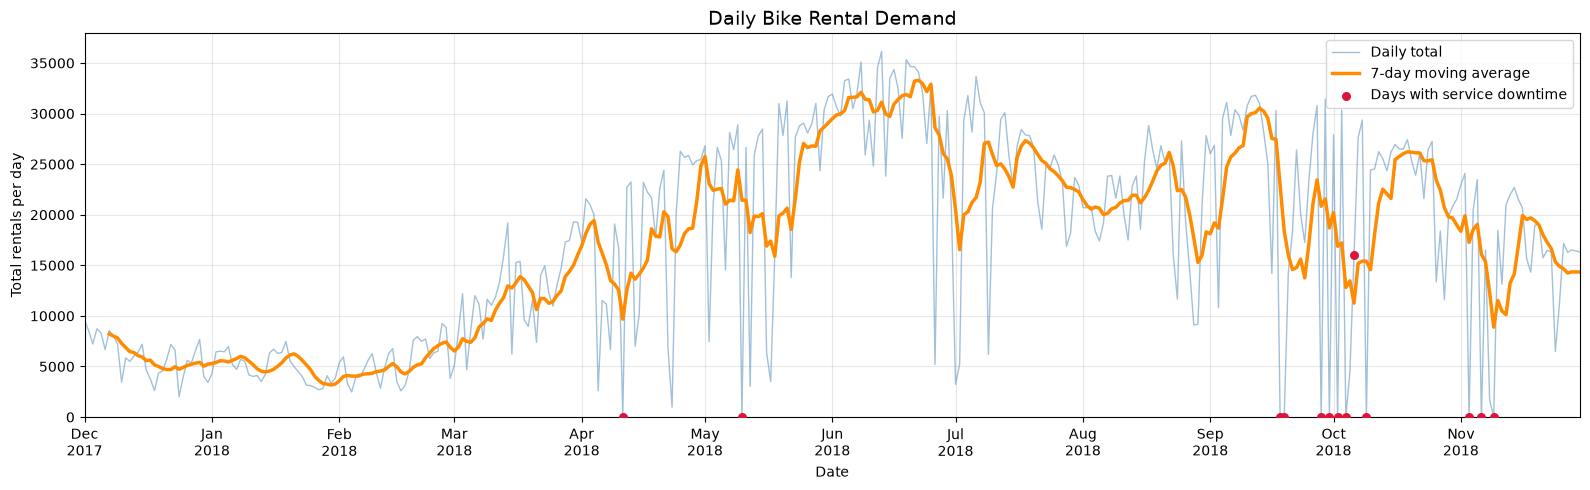

In [134]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

daily_demand = (
    df.groupby("date")["rented_bike_count"]
    .sum(min_count=1)
    .sort_index()
    .rename("daily_rentals")
    .to_frame()
)

daily_demand["rolling_mean_7d"] = (
    daily_demand["daily_rentals"]
    .rolling(window=7, min_periods=7)
    .mean()
)

if "functioning_day" in df.columns:
    non_operating_hours = (
        df["functioning_day"]
        .eq("No")
        .groupby(df["date"])
        .sum()
    )

    daily_demand["non_operating_hours"] = (
        non_operating_hours.reindex(daily_demand.index, fill_value=0)
    )

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    daily_demand.index,
    daily_demand["daily_rentals"],
    color="steelblue",
    linewidth=1,
    alpha=0.5,
    label="Daily total",
)

ax.plot(
    daily_demand.index,
    daily_demand["rolling_mean_7d"],
    color="darkorange",
    linewidth=2.5,
    label="7-day moving average",
)

if "non_operating_hours" in daily_demand.columns:
    affected_days = daily_demand[
        daily_demand["non_operating_hours"] > 0
    ]

    if not affected_days.empty:
        ax.scatter(
            affected_days.index,
            affected_days["daily_rentals"],
            color="crimson",
            s=30,
            zorder=3,
            label="Days with service downtime",
        )

ax.set_title("Daily Bike Rental Demand", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Total rentals per day")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

ax.set_xlim(daily_demand.index.min(), daily_demand.index.max())
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

In [133]:
s = daily_demand["daily_rentals"]

print("=" * 60)
print("DAILY DEMAND SUMMARY")
print("=" * 60)

print(f"Количество дней:          {len(s):,}")
print(f"Всего аренд за период:    {s.sum():,.0f}")
print(f"Среднее за день:          {s.mean():,.1f}")
print(f"Медиана за день:          {s.median():,.1f}")
print(f"Минимальный спрос:        {s.min():,.0f} ({s.idxmin():%Y-%m-%d})")
print(f"Максимальный спрос:       {s.max():,.0f} ({s.idxmax():%Y-%m-%d})")
print(f"Дней с нулевым спросом:   {s.eq(0).sum():,}")

if "non_operating_hours" in daily_demand.columns:
    downtime = daily_demand["non_operating_hours"]

    print(f"Дней с остановками:       {downtime.gt(0).sum():,}")
    print(f"Из них полностью без работы: {downtime.eq(24).sum():,}")

DAILY DEMAND SUMMARY
Количество дней:          365
Всего аренд за период:    6,172,314
Среднее за день:          16,910.4
Медиана за день:          17,730.0
Минимальный спрос:        0 (2018-04-11)
Максимальный спрос:       36,149 (2018-06-13)
Дней с нулевым спросом:   12
Дней с остановками:       13
Из них полностью без работы: 12


#### Observations

- За исследуемые 365 дней зарегистрировано 6 172 314 аренд.
  Среднее дневное количество аренд — 16 910, медиана — 17 730.
- В зимние месяцы спрос ниже; с марта наблюдается рост,
  а наиболее высокий устойчивый уровень приходится на июнь.
- Максимальная дневная сумма — 36 149 аренд — зафиксирована
  13 июня 2018 года.
- Выявлено 12 дней полной остановки сервиса и один день
  с частичной остановкой. Нулевые дневные суммы в эти дни
  нельзя интерпретировать как отсутствие пользовательского спроса.
- Отдельные резкие снижения наблюдаются и без отмеченных остановок.
  Их возможную связь с погодой и календарными факторами
  необходимо проверить отдельно.
- Данные охватывают только один год: виден внутригoдовой рисунок,
  но его повторяемость по годам пока не проверена.

### Hourly Demand by Day Type
[Index](#Time-Series-EDA-Index)


Сравнение среднего почасового количества аренд в будни,
выходные и праздники. Праздники выделены в отдельную категорию
независимо от дня недели. Учитываются только часы работы сервиса.

DAY TYPE SUMMARY — operating hours only


,calendar_days,days_with_service,operating_hours,mean_hourly_rentals
day_type,,,,
Weekday,247,238,5712,756.2
Weekend,100,98,2345,698.1
Holiday,18,17,408,529.2


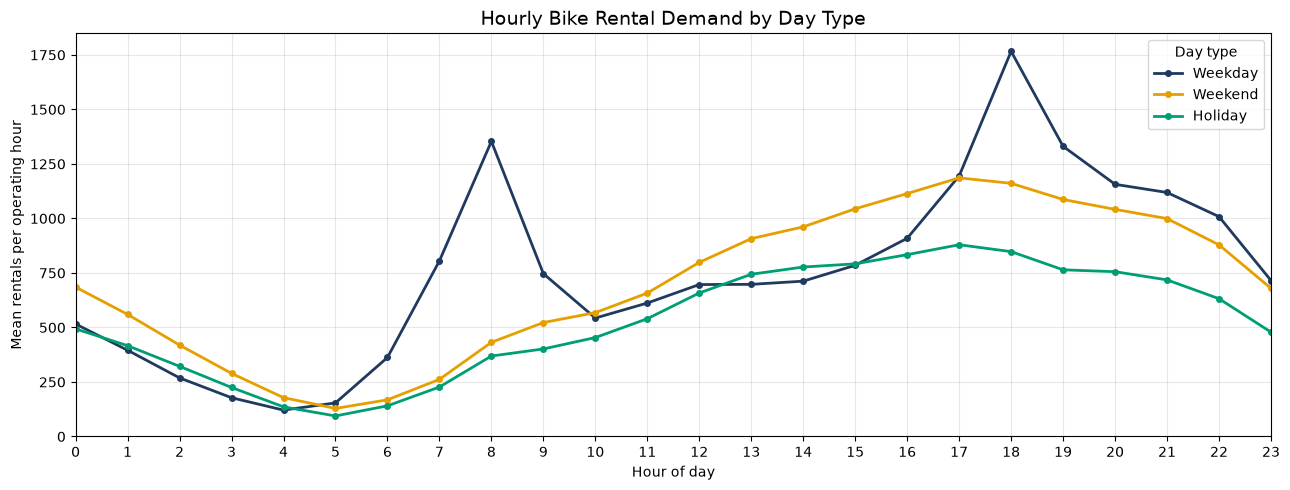

In [139]:
import matplotlib.pyplot as plt
import numpy as np

day_type_eda = df.copy()

# Понедельник = 0, воскресенье = 6.
day_type_eda["day_of_week"] = day_type_eda["date"].dt.day_of_week
day_type_eda["is_weekend"] = day_type_eda["day_of_week"].isin([5, 6])

# Проверяем метки, чтобы неизвестное значение не стало обычным будним днём.
if not day_type_eda["holiday"].isin(["Holiday", "No Holiday"]).all():
    raise ValueError("Проверь значения в колонке holiday")

if not day_type_eda["functioning_day"].isin(["Yes", "No"]).all():
    raise ValueError("Проверь значения в колонке functioning_day")

# Праздник имеет приоритет над выходным.
day_type_eda["day_type"] = np.select(
    [
        day_type_eda["holiday"].eq("Holiday"),
        day_type_eda["is_weekend"],
    ],
    [
        "Holiday",
        "Weekend",
    ],
    default="Weekday",
)

day_order = ["Weekday", "Weekend", "Holiday"]

# Размеры групп до фильтрации.
calendar_days = (
    day_type_eda.groupby("day_type")["date"]
    .nunique()
    .reindex(day_order)
)

# Только часы, когда сервис работал.
operating = day_type_eda.loc[
    day_type_eda["functioning_day"].eq("Yes")
].copy()

# Сводка по объёму данных для каждой группы.
group_summary = (
    operating.groupby("day_type")
    .agg(
        days_with_service=("date", "nunique"),
        operating_hours=("hour", "size"),
        mean_hourly_rentals=("rented_bike_count", "mean"),
    )
    .reindex(day_order)
)

group_summary.insert(0, "calendar_days", calendar_days)

print("DAY TYPE SUMMARY — operating hours only")
display(group_summary.round(1))

# Среднее количество аренд для каждой пары «час + тип дня».
hourly_profiles = (
    operating.pivot_table(
        index="hour",
        columns="day_type",
        values="rented_bike_count",
        aggfunc="mean",
    )
    .reindex(index=range(24), columns=day_order)
)

colors = {
    "Weekday": "#1F3A5F",
    "Weekend": "#E69F00",
    "Holiday": "#009E73",
}

fig, ax = plt.subplots(figsize=(13, 5))

for day_type in day_order:
    ax.plot(
        hourly_profiles.index,
        hourly_profiles[day_type],
        marker="o",
        markersize=4,
        linewidth=2,
        color=colors[day_type],
        label=day_type,
    )

ax.set_title("Hourly Bike Rental Demand by Day Type", fontsize=14)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean rentals per operating hour")
ax.set_xticks(range(24))
ax.set_xlim(0, 23)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend(title="Day type")

fig.tight_layout()
plt.show()

In [138]:
peak_summary = pd.DataFrame({
    "peak_hour": hourly_profiles.idxmax(),
    "peak_mean_rentals": hourly_profiles.max(),
    "lowest_hour": hourly_profiles.idxmin(),
    "lowest_mean_rentals": hourly_profiles.min(),
}).reindex(day_order)

display(peak_summary.round(1))

,peak_hour,peak_mean_rentals,lowest_hour,lowest_mean_rentals
day_type,,,,
Weekday,18,1766.3,4,121.0
Weekend,17,1186.1,5,128.7
Holiday,17,879.4,5,94.2


#### Observations

- В будни наблюдаются два выраженных пика среднего почасового спроса:
  утренний около 08:00 и вечерний в 18:00.
  Максимальное среднее значение — 1766 аренд в 18:00.
- В выходные выраженный утренний пик отсутствует. Спрос постепенно
  растёт в течение дня и достигает максимума в 17:00 — 1186 аренд.
- Праздничный профиль по форме ближе к выходному, но средний уровень
  аренд ниже. Максимум — 879 аренд в 17:00.
- Объединение будней и выходных в категорию No Holiday скрывало
  различия их суточных профилей.
- Анализ выполнен только по часам работы сервиса. Праздники
  представлены 17 днями с работающим сервисом, поэтому выводы
  по этой группе требуют большей осторожности.
- Профили усреднены за весь год: различия погоды и сезонного состава
  групп в этом сравнении отдельно не учитываются.

#### Feature Engineering Ideas

- Создать признаки циклического расстояния до пиковых часов:
  - hour_dist_to_8 — расстояние до 08:00;
  - hour_dist_to_18 — расстояние до 18:00.
- Расстояние считать по 24-часовому кругу:
  d(h, p) = min(|h − p|, 24 − |h − p|).
- Дополнительно проверить расстояние до ближайшего пика:
  hour_dist_to_peak = min(hour_dist_to_8, hour_dist_to_18).
- Проверить взаимодействие с типом дня: утренний пик выражен
  прежде всего в будни.
- Полезность признаков проверить на временной валидации
  относительно модели с исходным hour.
- При подборе пиков по данным использовать только обучающую
  часть, не весь датасет.


```python
for peak in [8, 18]:
    distance = (df["hour"] - peak).abs()
    df[f"hour_dist_to_{peak}"] = np.minimum(distance, 24 - distance)

df["hour_dist_to_peak"] = df[
    ["hour_dist_to_8", "hour_dist_to_18"]
].min(axis=1)
```

### Demand Autocorrelation
[Index](#Time-Series-EDA-Index)


Анализ автокорреляции почасового количества аренд:
краткосрочной зависимости, суточного и недельного рисунка.
Используется полный временной ряд, включая часы остановки сервиса.

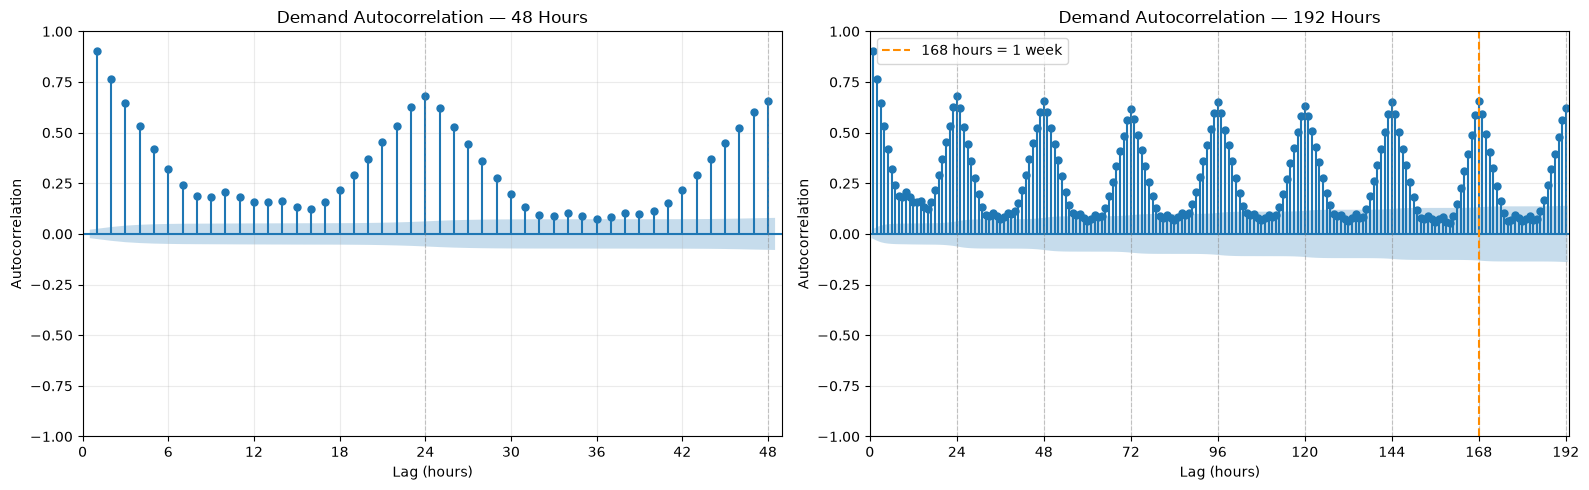

In [142]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf

# Создаём отдельную таблицу, не меняя df.
acf_data = df[["date", "hour", "rented_bike_count"]].copy()

acf_data["datetime"] = (
    acf_data["date"]
    + pd.to_timedelta(acf_data["hour"], unit="h")
)

demand_ts = (
    acf_data
    .set_index("datetime")["rented_bike_count"]
    .sort_index()
)

# Защита от случайного использования неполного или изменённого ряда.
if demand_ts.index.has_duplicates:
    raise ValueError("Обнаружены повторяющиеся временные отметки")

expected_index = pd.date_range(
    start="2017-12-01 00:00",
    end="2018-11-30 23:00",
    freq="h",
)

if not demand_ts.index.equals(expected_index):
    raise ValueError("Ряд не соответствует ожидаемой почасовой сетке")

if not np.isfinite(demand_ts.to_numpy(dtype=float)).all():
    raise ValueError("В целевой переменной есть пропуски или бесконечности")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, max_lag, tick_step in zip(
    axes,
    [48, 192],
    [6, 24],
):
    plot_acf(
        demand_ts,
        lags=max_lag,
        zero=False,
        fft=True,
        missing="raise",
        ax=ax,
        title=f"Demand Autocorrelation — {max_lag} Hours",
    )

    # Отмечаем суточные интервалы.
    for lag in range(24, max_lag + 1, 24):
        ax.axvline(
            lag,
            color="gray",
            linestyle="--",
            linewidth=0.8,
            alpha=0.4,
        )

    # На правой панели отдельно выделяем неделю.
    if max_lag >= 168:
        ax.axvline(
            168,
            color="darkorange",
            linestyle="--",
            linewidth=1.5,
            label="168 hours = 1 week",
        )
        ax.legend()

    ax.set_xlabel("Lag (hours)")
    ax.set_ylabel("Autocorrelation")
    ax.set_xticks(range(0, max_lag + 1, tick_step))
    ax.set_xlim(0, max_lag + 1)
    ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

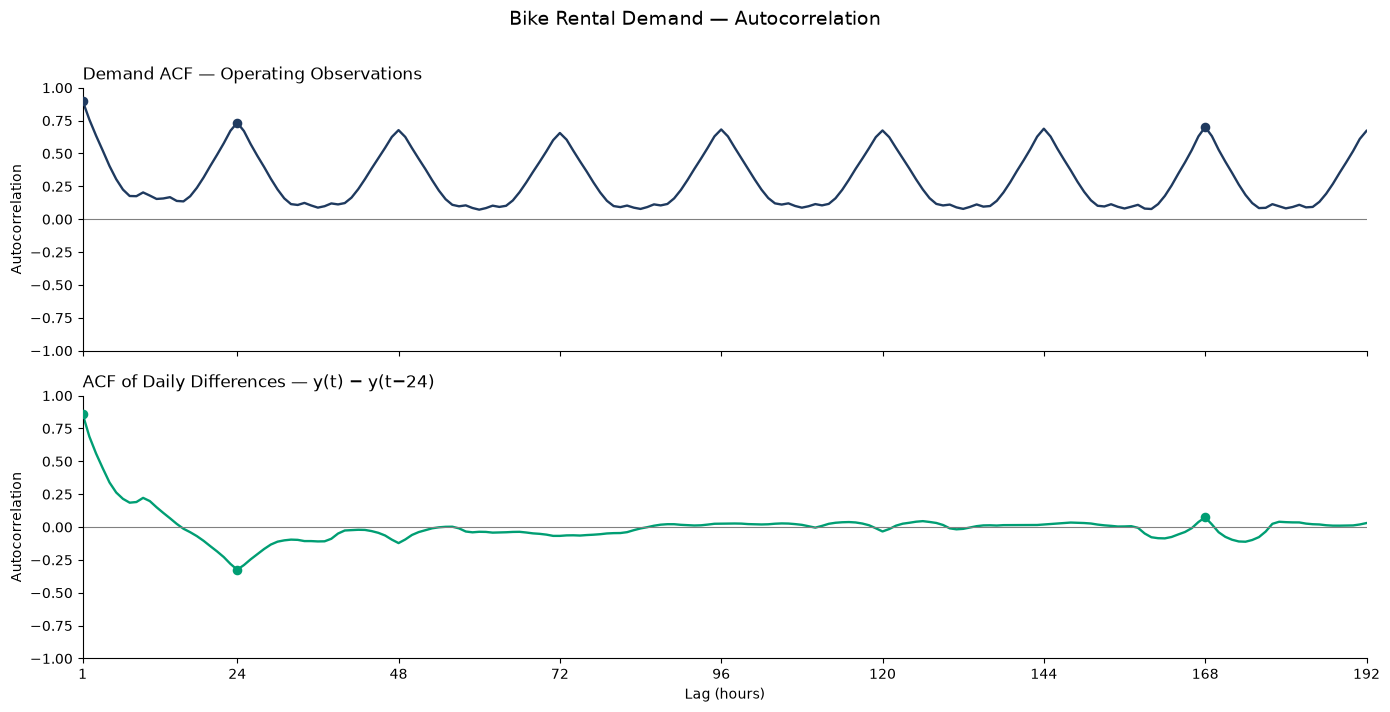

In [145]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

# Полная почасовая сетка уже проверена в Temporal Integrity Check.
acf_data = df[
    ["date", "hour", "rented_bike_count", "functioning_day"]
].copy()

acf_data["datetime"] = (
    acf_data["date"]
    + pd.to_timedelta(acf_data["hour"], unit="h")
)

acf_data = acf_data.set_index("datetime").sort_index()

# Сохраняем временную шкалу, но исключаем остановки из расчёта.
working_demand = (
    acf_data["rented_bike_count"]
    .astype(float)
    .where(acf_data["functioning_day"].eq("Yes"))
)

# Разность существует только тогда, когда оба сравниваемых часа рабочие.
daily_difference = working_demand - working_demand.shift(24)

max_lag = 192
lags = np.arange(1, max_lag + 1)

series_to_plot = [
    (
        working_demand,
        "Demand ACF — Operating Observations",
        "#1F3A5F",
    ),
    (
        daily_difference,
        "ACF of Daily Differences — y(t) − y(t−24)",
        "#009E73",
    ),
]

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True,
    sharey=True,
)

for ax, (series, title, color) in zip(axes, series_to_plot):
    acf_values = acf(
        series,
        nlags=max_lag,
        fft=True,
        missing="conservative",
    )

    ax.plot(
        lags,
        acf_values[1:],
        color=color,
        linewidth=1.7,
    )

    # Выделяем только основные интересующие лаги.
    selected_lags = np.array([1, 24, 168])

    ax.scatter(
        selected_lags,
        acf_values[selected_lags],
        color=color,
        s=35,
        zorder=3,
    )

    ax.axhline(0, color="gray", linewidth=0.8)

    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylabel("Autocorrelation")
    ax.set_ylim(-1, 1)

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xticks([1, 24, 48, 72, 96, 120, 144, 168, 192])
axes[-1].set_xlim(1, max_lag)
axes[-1].set_xlabel("Lag (hours)")

fig.suptitle(
    "Bike Rental Demand — Autocorrelation",
    fontsize=14,
    y=1.01,
)

fig.tight_layout()
plt.show()

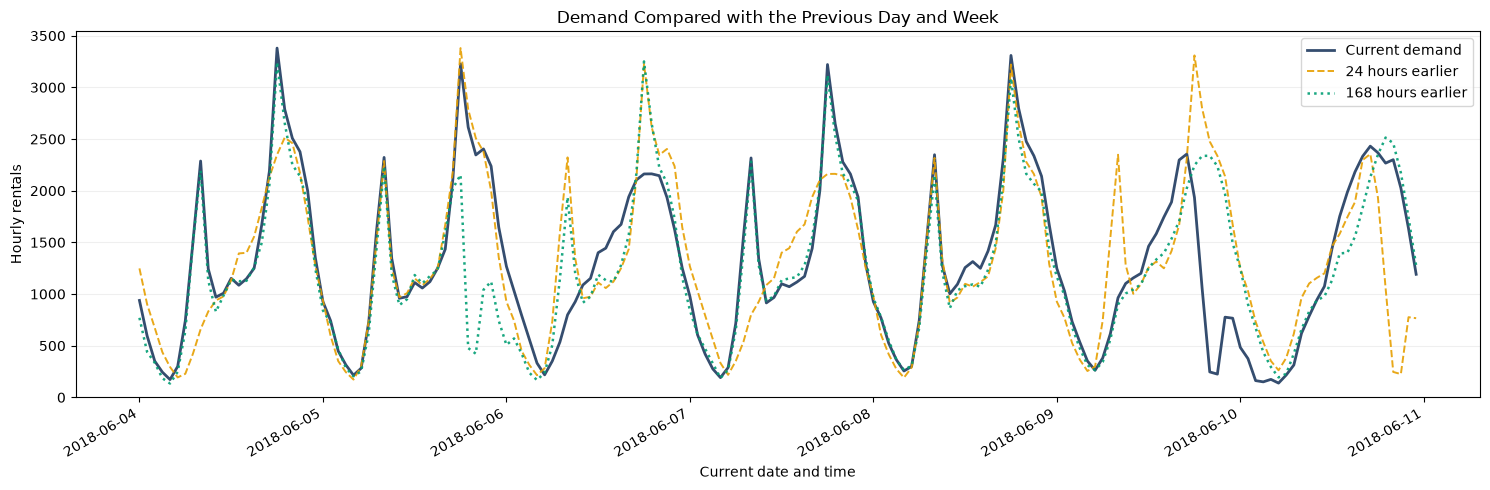

In [146]:
# Сначала сдвигаем полный ряд, затем выбираем неделю.
comparison = pd.DataFrame({
    "Current demand": working_demand,
    "24 hours earlier": working_demand.shift(24),
    "168 hours earlier": working_demand.shift(168),
})

# Пример недели для визуального сравнения.
week = comparison.loc["2018-06-04":"2018-06-10"]

fig, ax = plt.subplots(figsize=(15, 5))

styles = {
    "Current demand": ("#1F3A5F", "-", 2.0),
    "24 hours earlier": ("#E69F00", "--", 1.4),
    "168 hours earlier": ("#009E73", ":", 1.8),
}

for col, (color, linestyle, linewidth) in styles.items():
    ax.plot(
        week.index,
        week[col],
        label=col,
        color=color,
        linestyle=linestyle,
        linewidth=linewidth,
        alpha=0.9,
    )

ax.set_title("Demand Compared with the Previous Day and Week")
ax.set_xlabel("Current date and time")
ax.set_ylabel("Hourly rentals")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [143]:
lag_labels = {
    1: "Previous hour",
    24: "Same hour yesterday",
    168: "Same hour last week",
}

lag_summary = pd.DataFrame([
    {
        "lag_hours": lag,
        "description": description,
        "pearson_correlation": demand_ts.corr(demand_ts.shift(lag)),
        "n_pairs": len(demand_ts) - lag,
    }
    for lag, description in lag_labels.items()
]).set_index("lag_hours")

display(lag_summary.round(4))

,description,pearson_correlation,n_pairs
lag_hours,,,
1,Previous hour,0.9035,8759
24,Same hour yesterday,0.6819,8736
168,Same hour last week,0.6607,8592


#### Observations

- Почасовой спрос имеет повторяющийся суточный рисунок.
- Корреляция с предыдущим часом составляет 0.9035,
  с тем же часом предыдущего дня — 0.6819,
  с тем же часом предыдущей недели — 0.6607.
  Эти значения рассчитаны по полному ряду, включая остановки сервиса.
- На выбранной неделе сдвинутые ряды часто воспроизводят время
  подъёмов и спадов, но не всегда их величину.
- Лаги 1, 24 и 168 часов рассматриваются как кандидаты в признаки,
  а не как гарантированное улучшение модели.
- Для оценки их практической пользы на этапе моделирования
  нужно сравнить прогнозы с простыми ориентирами:
  «как вчера в этот час» и «как неделю назад».

### Hourly Demand by Season

Среднее количество аренд по часам суток в разные сезоны.
Учитываются только часы работы сервиса.

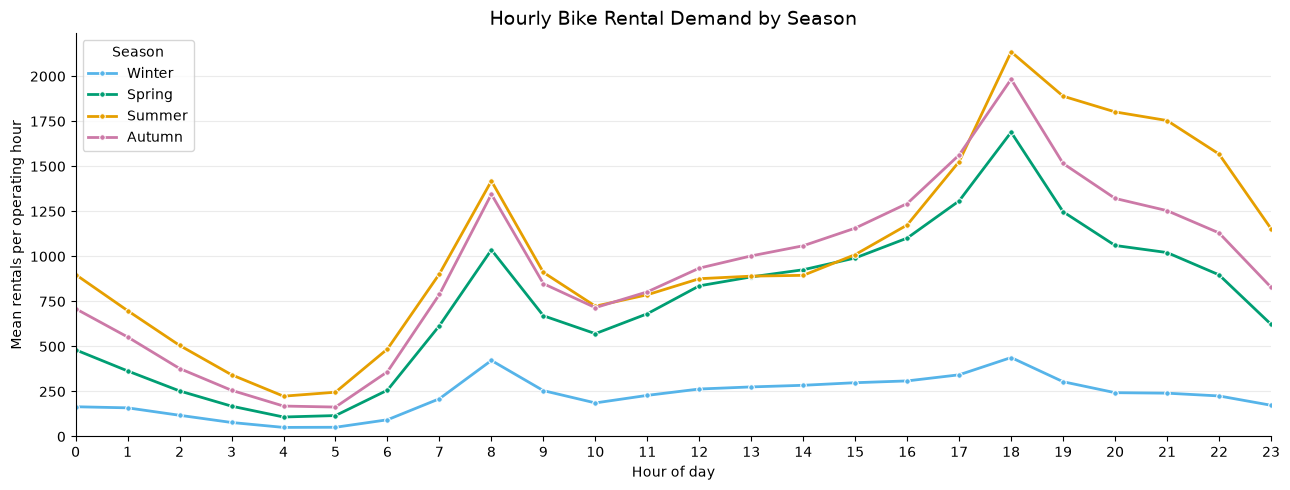

In [147]:
import matplotlib.pyplot as plt
import seaborn as sns

season_eda = df.loc[df["functioning_day"].eq("Yes")].copy()

season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_palette = {
    "Winter": "#56B4E9",
    "Spring": "#009E73",
    "Summer": "#E69F00",
    "Autumn": "#CC79A7",
}

fig, ax = plt.subplots(figsize=(13, 5))

sns.lineplot(
    data=season_eda,
    x="hour",
    y="rented_bike_count",
    hue="seasons",
    hue_order=season_order,
    palette=season_palette,
    estimator="mean",
    errorbar=None,
    marker="o",
    linewidth=2,
    markersize=4,
    ax=ax,
)

ax.set_title(
    "Hourly Bike Rental Demand by Season",
    fontsize=14,
)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean rentals per operating hour")
ax.set_xticks(range(24))
ax.set_xlim(0, 23)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Season")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

In [125]:
print("=" * 80)
print("AVERAGE RENTED BIKE COUNT BY HOUR")
print("=" * 80)

print("\n▶ Overall by hour (0–23):")
overall = df.groupby('hour')['rented_bike_count'].mean().round(1)
print(overall.to_string())

print("\n▶ By hour: Holiday vs No Holiday (mean):")
by_holiday = df.pivot_table(
    index='hour', columns='holiday',
    values='rented_bike_count', aggfunc='mean'
).round(1)
print(by_holiday.to_string())

print("\n▶ By hour: Seasons (mean):")
by_season = df.pivot_table(
    index='hour', columns='seasons',
    values='rented_bike_count', aggfunc='mean'
).round(1)
print(by_season.to_string())

print("\n" + "=" * 80)
print("PEAK / LOW HOURS BY HOLIDAY")
print("=" * 80)

for label, subset in df.groupby('holiday'):
    grp = subset.groupby('hour')['rented_bike_count'].mean().dropna()

    if len(grp) == 0:
        print(f"  {label:<15} → нет данных")
        continue

    peak_h = grp.idxmax()
    low_h  = grp.idxmin()
    print(f"  {label:<15} peak hour = {peak_h:>2} ({grp.max():.1f})  |  "
          f"low hour = {low_h:>2} ({grp.min():.1f})")

AVERAGE RENTED BIKE COUNT BY HOUR

▶ Overall by hour (0–23):
hour
0      541.5
1      426.2
2      301.6
3      203.3
4      132.6
5      139.1
6      287.6
7      606.0
8     1015.7
9      646.0
10     527.8
11     600.9
12     699.4
13     733.2
14     758.8
15     829.2
16     930.6
17    1138.5
18    1502.9
19    1195.1
20    1069.0
21    1031.4
22     922.8
23     671.1

▶ By hour: Holiday vs No Holiday (mean):
holiday  Holiday  No Holiday
hour                        
0          466.2       545.4
1          393.3       427.9
2          303.9       301.5
3          212.3       202.9
4          128.4       132.8
5           89.0       141.7
6          132.8       295.6
7          214.3       626.3
8          348.5      1050.3
9          379.2       659.8
10         428.6       533.0
11         510.0       605.6
12         621.6       703.5
13         702.7       734.8
14         734.0       760.1
15         747.8       833.4
16         787.6       938.0
17         830.5      1154.5


In [126]:
print("Уникальные значения holiday:", df['holiday'].unique())
print("\nКоличество по holiday:")
print(df['holiday'].value_counts(dropna=False))
print("\nУникальные значения hour:", sorted(df['hour'].unique())[:5], "...")
print("Пропуски в hour:", df['hour'].isna().sum())

Уникальные значения holiday: ['No Holiday', 'Holiday']
Categories (2, str): ['Holiday', 'No Holiday']

Количество по holiday:
holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

Уникальные значения hour: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] ...
Пропуски в hour: 0


### Time-Series EDA Summary
[Index](#Time-Series-EDA-Index)


#### Temporal Coverage

- Данные покрывают период с 1 декабря 2017 года, 00:00,
  по 30 ноября 2018 года, 23:00.
- Все 8760 почасовых наблюдений представлены ровно один раз:
  пропущенных часов и дубликатов временных отметок нет.
- Каждый из 365 дней содержит 24 наблюдения.
  Исходный порядок строк хронологический.

#### Daily Demand

- За период зарегистрировано 6 172 314 аренд.
  Среднее дневное количество — 16 910, медиана — 17 730.
- В зимние месяцы спрос ниже; с марта начинается рост.
  Наиболее высокий устойчивый уровень наблюдается в июне.
- Максимальный дневной спрос — 36 149 аренд —
  зафиксирован 13 июня 2018 года.
- Выявлены 12 дней полной и один день частичной остановки сервиса.
  Отсутствие аренд во время остановок нельзя трактовать
  как отсутствие пользовательского спроса.
- В ряде есть провалы, не объясняемые отмеченными остановками.
  Их причины требуют отдельного сопоставления с погодой
  и календарными факторами.

#### Day-Type Profiles

- В будни выражены утренний пик около 08:00 и вечерний в 18:00.
  Вечерний максимум составляет в среднем 1766 аренд.
- В выходные выраженный утренний пик отсутствует;
  максимум достигается в 17:00 — в среднем 1186 аренд.
- Праздничный профиль ближе к выходному, но уровень аренд ниже:
  максимум в 17:00 составляет в среднем 879 аренд.
- Категория No Holiday объединяла будни и выходные
  и скрывала различия их почасовых профилей.
- Эти профили рассчитаны только по часам работы сервиса.

#### Autocorrelation

- В полном фактическом ряду корреляция с лагом 1 час равна 0.9035,
  с лагом 24 часа — 0.6819, с лагом 168 часов — 0.6607.
- ACF показывает повторяющийся суточный рисунок.
  Корреляции отражают не только краткосрочную зависимость,
  но и календарные колебания и изменения общего уровня спроса.
- Сходство со вчерашним и недельным профилями не исключает
  значительных ошибок в отдельные часы.

#### Feature Engineering Candidates

- Рассмотреть признаки дня недели, выходного дня и типа дня.
- Проверить циклические расстояния до 08:00 и 18:00,
  а также их взаимодействия с типом дня.
- Рассмотреть лаги спроса 1, 24 и 168 часов, если они доступны
  на момент построения прогноза.
- Оценить пользу новых признаков на временной валидации.
  Пиковые часы, если они подбираются по данным,
  определять только по обучающей части.

#### Limitations

- Один год наблюдений позволяет описать внутригoдовую динамику,
  но не проверить её повторяемость в последующие годы.
- Сравнение типов дней выполнено без выравнивания
  по погоде и сезонам: различия не следует объяснять
  исключительно календарным типом дня.
- Праздники представлены только 17 днями с работающим сервисом.
- Анализ описывает фактические аренды, а не неудовлетворённый
  спрос пользователей.

## EDA Conclusion